# **FYS-STK3155 Project 2**: Feed-forward neural network for regression and classification

This notebook runs the experiments for Project 2 using the `scripts/part_*.py` files, makes the plots, and saves the figures and tables used in the report.

Before running the notebook:
- Run `uv sync` in the terminal.
- Select the project environment as the Jupyter kernel.


In [1]:
# To automatically reload modules when they are changed
%reload_ext autoreload
%autoreload

In [1]:
"""Tools used:
    - Copilot autocomplete
    - ChatGPT (October & November, 2026)
"""
from pathlib import Path

import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import project2
from project1.utils import runge_function
from project1.utils.report import save_figure, save_latex_table

import warnings

warnings.filterwarnings("ignore", module=r"sklearn(\..*)?$")  # Ignore all warnings from sklearn

jax.config.update("jax_enable_x64", True)  # type: ignore

PROJECT_ROOT = Path(project2.__file__).resolve().parents[2]  # meh, but easiest way # type: ignore

### PLEASE SET THESE TO NONE if you do not want to save figures and tables
FIGURES_DIR = PROJECT_ROOT / "figures"
TABLES_DIR = PROJECT_ROOT / "report" / "tables"

if FIGURES_DIR is not None:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
if TABLES_DIR is not None:
    TABLES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
BLUE = "#0072B2"
RED = "#D55E00"
YELLOW = "#E69F00"
GREEN = "#009E73"
PURPLE = "#CC79A7"
GREY = "#777777"
BLACK = "#000000"

TRAIN_COLOR = GREY
VALIDATION_COLOR = BLUE
TEST_COLOR = RED

SIGMOID_COLOR = BLUE
RELU_COLOR = RED
LEAKY_RELU_COLOR = GREEN

L1_COLOR = YELLOW
L2_COLOR = PURPLE

For parts b)–d), we use the same one-dimensional Runge data as in Project 1. The data is generated with the same sample size, noise level and random seed.

$n=100$ points, $x$ uniform on $[-1,1]$, $y=\frac{1}{1+25x^2}+\epsilon$ with $\epsilon\sim N(0,0.1^2)$. Seed $2026$ used throughout for reproducibility. The noise floor of every MSE in this notebook is therefore $\sigma^2=0.01$, and no model, however good, should do better than that on new data. 

In [4]:
N = 100
NOISE = 0.1
SEED = 2026
MAX_DEGREE = 15
TEST_SIZE = 0.2
LAMBDAS = np.logspace(-4, 2, 15)

# Same function and seed as Project 1.
x, y = runge_function(n=N, noise=NOISE, seed=SEED)

print(f"n = {len(y)}, noise sigma = {NOISE}, lambda grid = {LAMBDAS[0]:.1e} ... {LAMBDAS[-1]:.1e}")


n = 100, noise sigma = 0.1, lambda grid = 1.0e-04 ... 1.0e+02


We split the data in training and test sets. We will **not** touch the test set when choosing hyperparameters. 

In [5]:
from sklearn.model_selection import train_test_split

# Split the data into training and test sets.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=SEED)

# Reshape the input data for neural networks.
x_train = x_train.reshape(-1, 1)
x_test = x_test.reshape(-1, 1)

# to have dims (n_samples, 1)
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

print(f"x_train shape: {x_train.shape}, x_test shape: {x_test.shape}")
print(f"y_train shape: {y_train.shape}, y_test shape: {y_test.shape}")


x_train shape: (80, 1), x_test shape: (20, 1)
y_train shape: (80, 1), y_test shape: (20, 1)


## **Results from project 1**:

Cross-validation, with one standard error rule, picked:
- OLS: degree $10$
- Ridge: degree $6$, $\lambda=1.8\times 10^{-3}$
- Lasso: degree $6$, $\lambda=1.8\times 10^{-3}$

In [6]:
# From project 1

OLS_BEST_DEGREE = 10
RIDGE_BEST_DEGREE = 6
LASSO_BEST_DEGREE = 6

RIDGE_BEST_LAMBDA = 1.8e-3
LASSO_BEST_LAMBDA = 1.8e-3

### **Part b):** FFNN for regression

We first use feed-forward neural network for the Runge regression problem, with mean squared error (MSE) as cost function, and no regularization.

We are asked to study:
- one hidden layer with 50 nodes
- two hidden layers with 100 nodes each
- plain gradient descent with different learning rates
- stochastic/minibatch using RMSprop and Adam.

We are asked to only use the Sigmoid function as activation function for the hidden layers.

We will also compare our results with the best OLS result from project 1.

##### **One hidden layer with 50 nodes**

FFNN with Adam, 1000 epochs, $\gamma=0.01$. Full-batch. Same hyperparameters for Scikit-Learn's MLP.

In [12]:
from project2.scripts import part_b

x_grid = np.linspace(-1.0, 1.0, 400).reshape(-1, 1)

result_b_50 = part_b.fit_comparison(
    x_train=x_train,
    y_train=y_train,
    x_grid=x_grid,
    ols_best_degree=OLS_BEST_DEGREE,
    batch_size=x_train.shape[0],
    epochs=1000,
)

print("Parameters:")
for model, info in result_b_50.items():
    print(f"{model}: {info['n_parameters']}")

Parameters:
Analytical OLS: 11
Our FFNN: 151
Scikit-Learn MLP: 151


Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_b_comparison_50.pdf


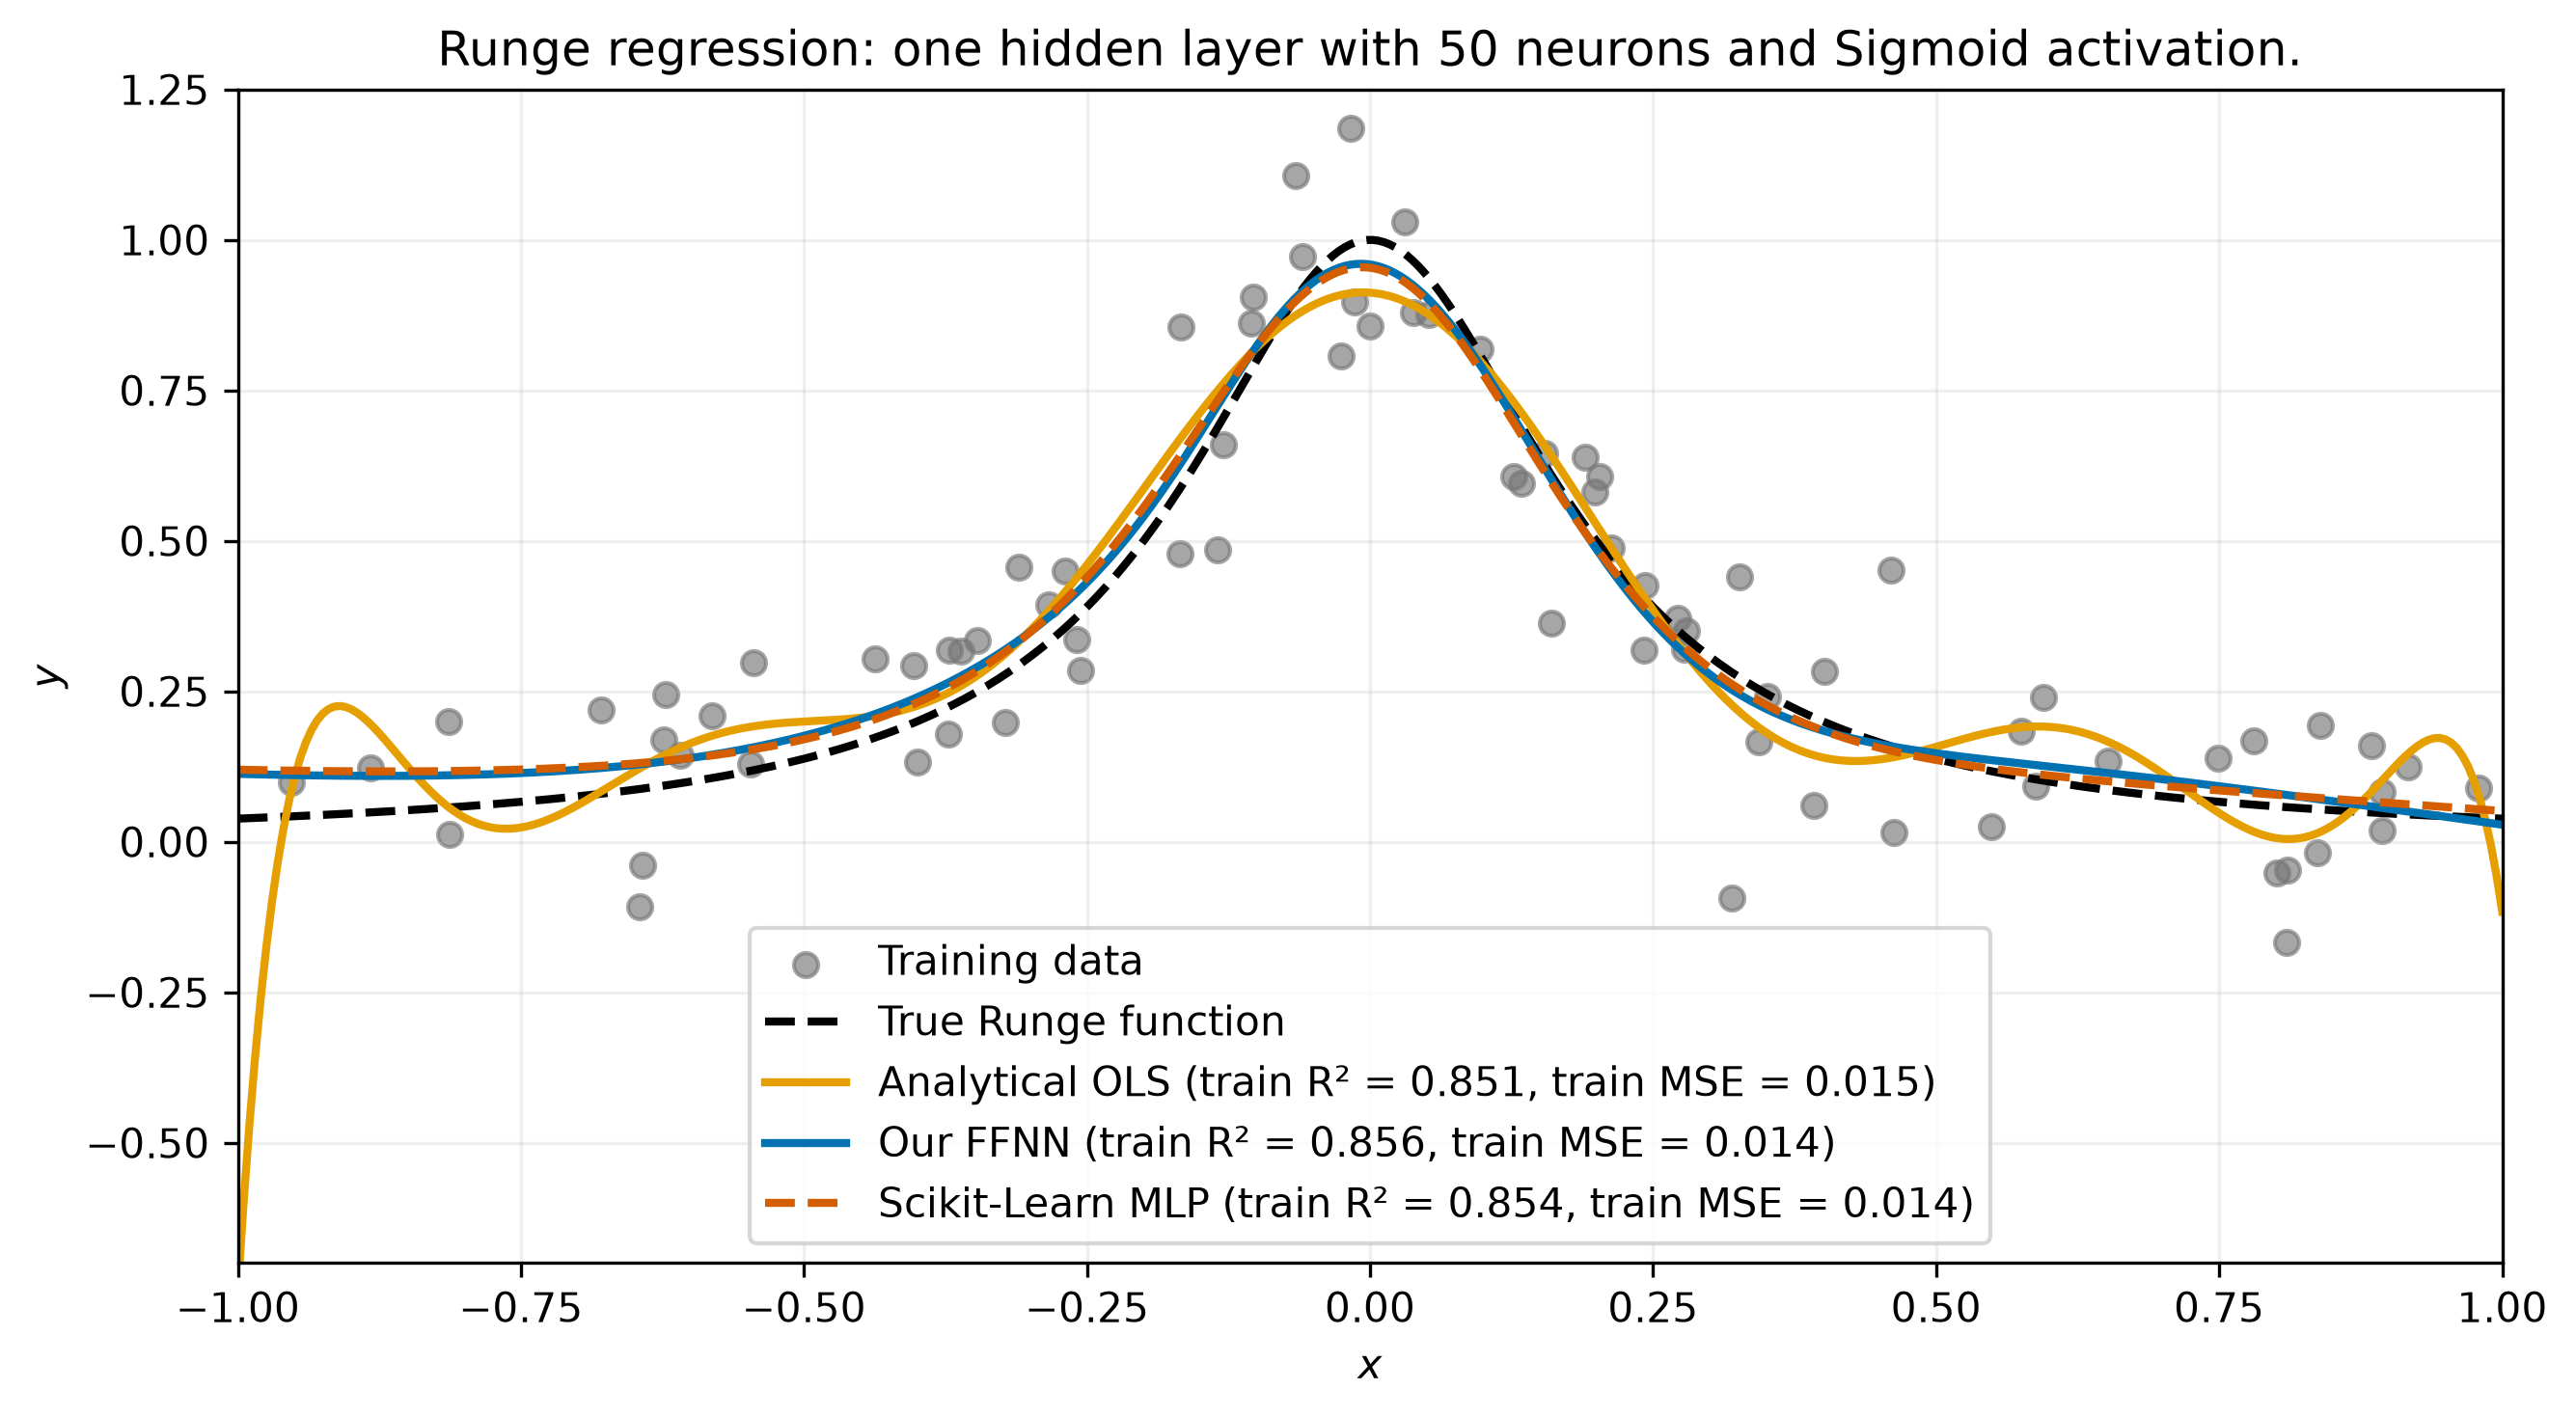

In [8]:
model_colors = {"Analytical OLS": YELLOW, "Our FFNN": BLUE, "Scikit-Learn MLP": RED}
y_true = 1.0 / (1.0 + 25.0 * x_grid**2)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x_train, y_train, color=TRAIN_COLOR, alpha=0.65, label="Training data")
ax.plot(x_grid, y_true, color=BLACK, linestyle="--", linewidth=2, label="True Runge function")

for model_name, model_result in result_b_50.items():
    ax.plot(
        x_grid,
        model_result["grid_prediction"],
        color=model_colors[model_name],
        linewidth=2,
        linestyle="--" if model_name == "Scikit-Learn MLP" else "-",
        label=f"{model_name} "
        f"(train R² = {model_result['train_r2']:.3f}, train MSE = {model_result['MSE']:.3f})",
    )

ax.set(
    xlabel="$x$",
    ylabel="$y$",
    title="Runge regression: one hidden layer with 50 neurons and Sigmoid activation.",
    xlim=(-1, 1),
    ylim=(-0.7, 1.25),
)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_b_comparison_50.pdf")
plt.show()

##### **Two hidden layers with 100 nodes each**

FFNN with Adam, 1000 epochs, $\gamma=0.01$. Full-batch. Same hyperparameters for Scikit-Learn's MLP.

In [9]:
result_b_100 = part_b.fit_comparison(
    x_train=x_train,
    y_train=y_train,
    x_grid=x_grid,
    hidden_sizes=(100, 100),
    ols_best_degree=OLS_BEST_DEGREE,
    batch_size=x_train.shape[0],
    epochs=1000,
)

print("Parameters:")
for model, info in result_b_100.items():
    print(f"{model}: {info['n_parameters']}")

Parameters:
Analytical OLS: 11
Our FFNN: 10401
Scikit-Learn MLP: 10401


Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_b_comparison_100.pdf


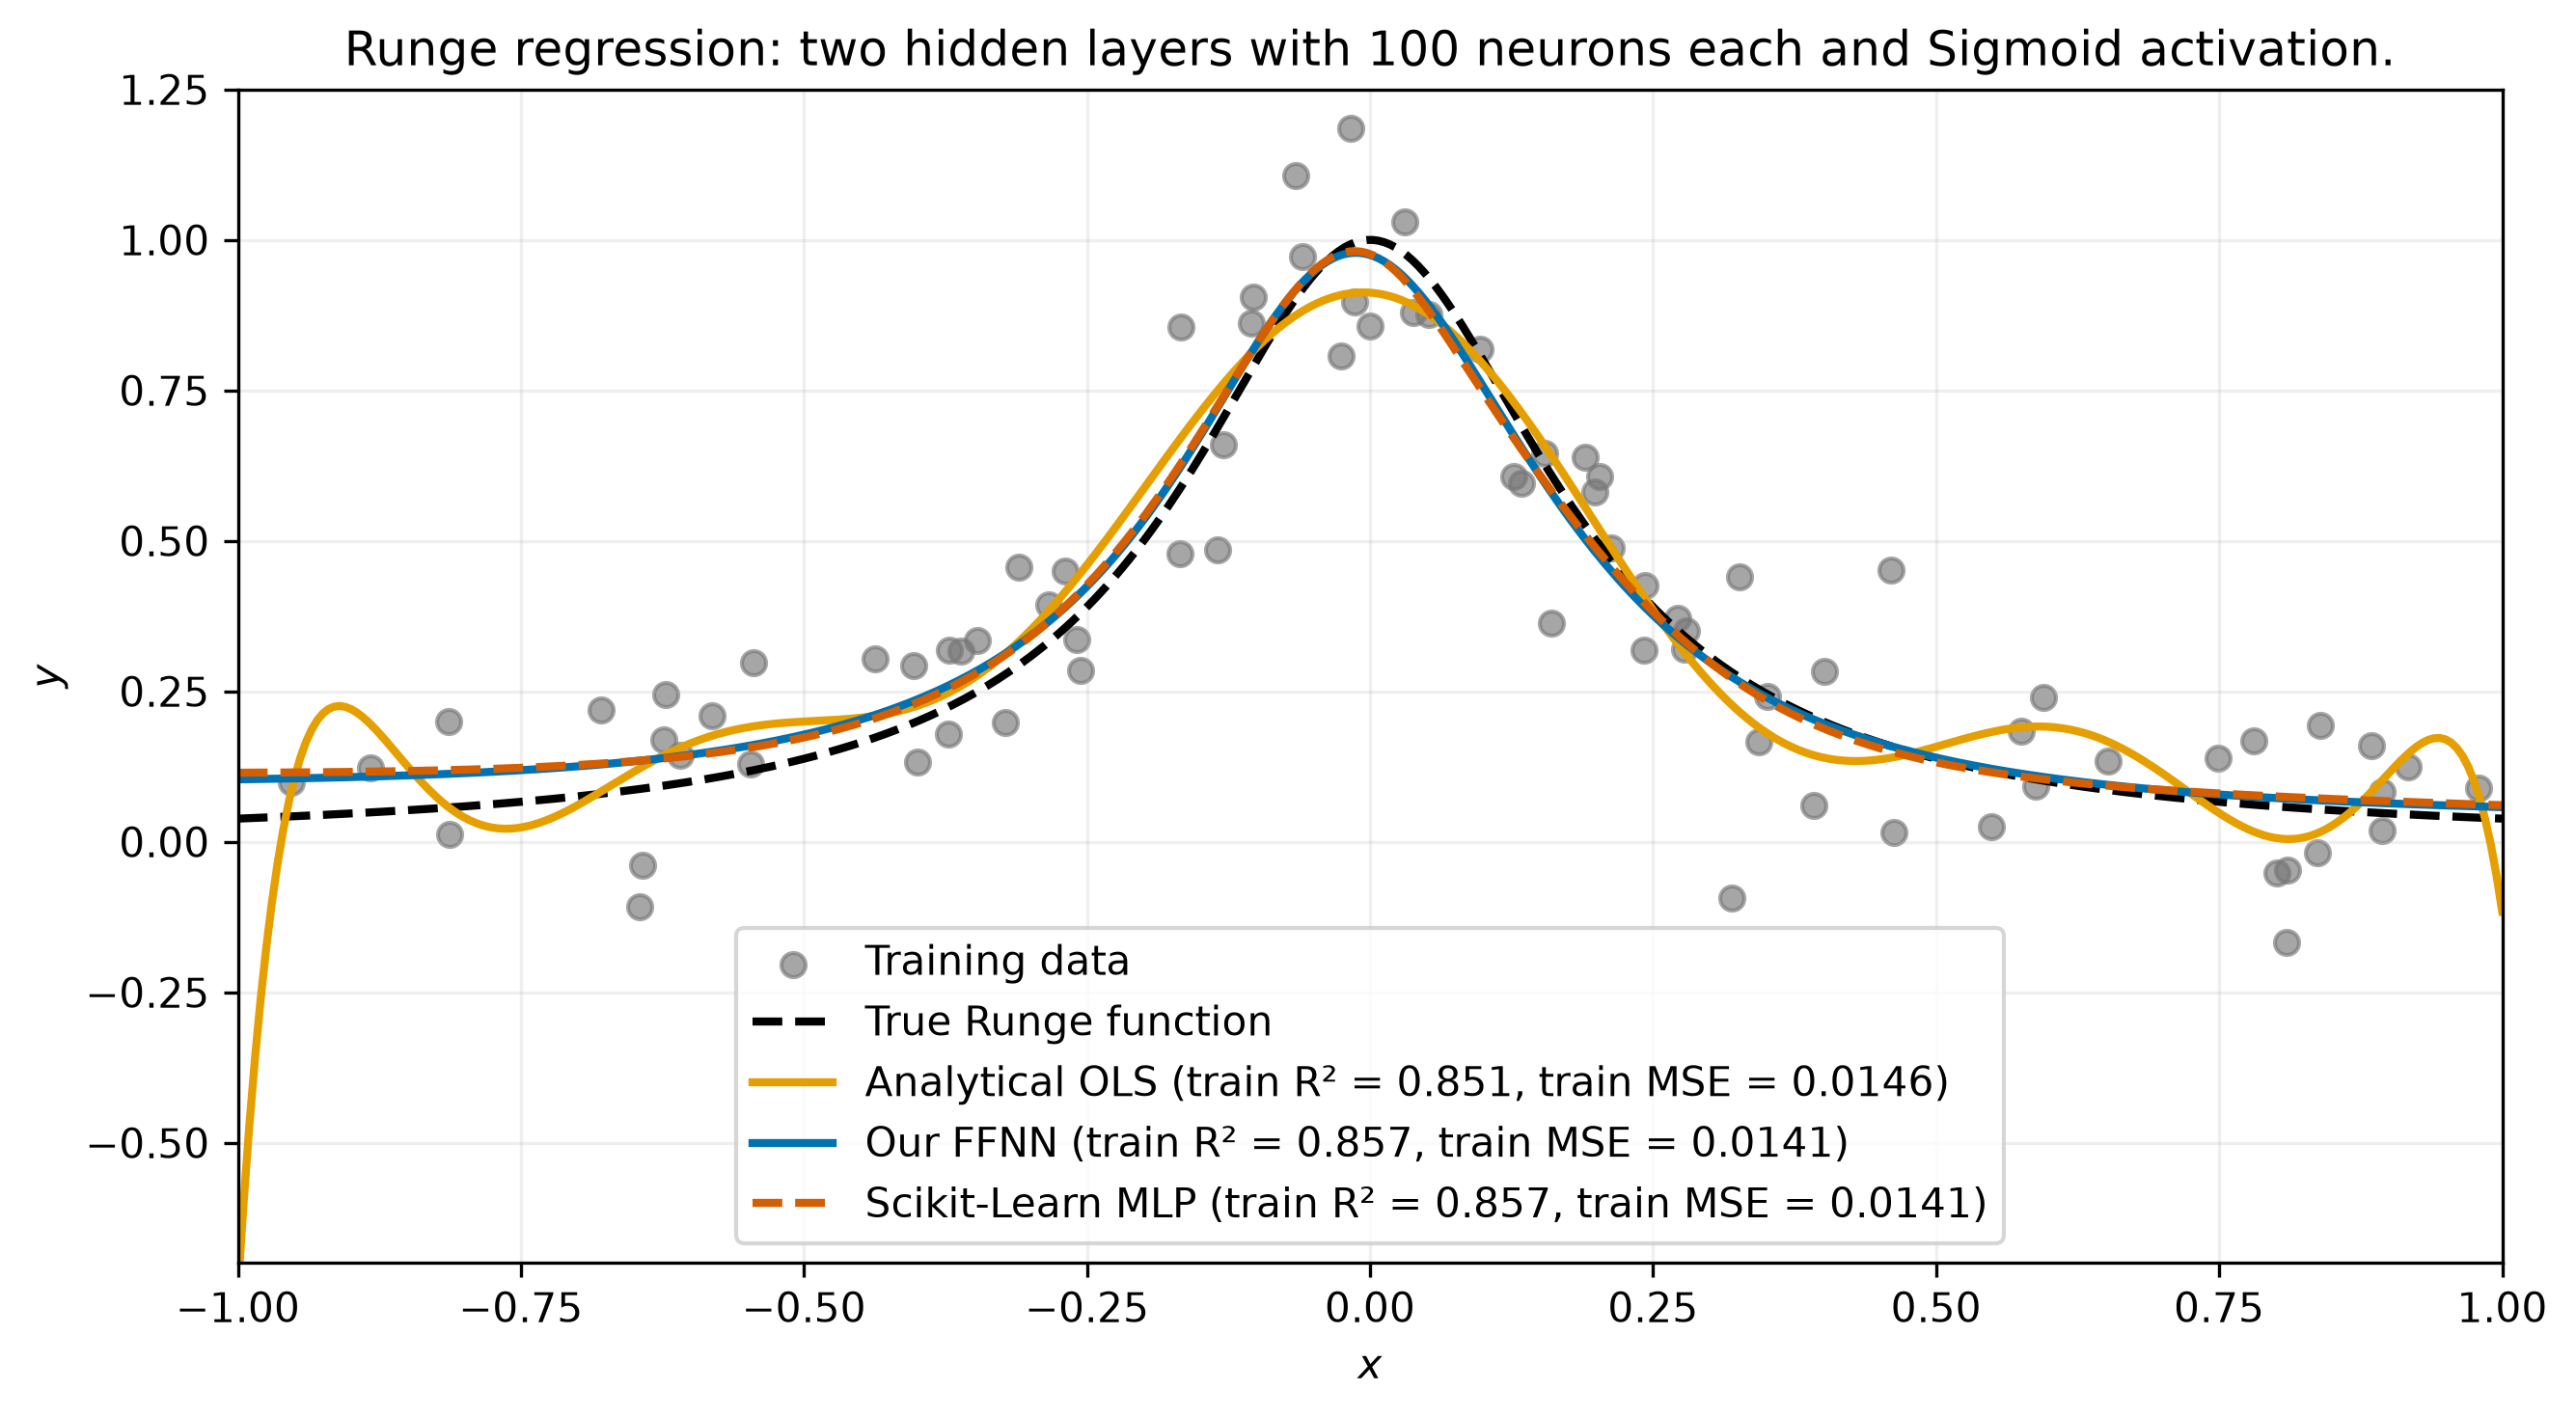

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x_train, y_train, color=TRAIN_COLOR, alpha=0.65, label="Training data")
ax.plot(x_grid, y_true, color=BLACK, linestyle="--", linewidth=2, label="True Runge function")

for model_name, model_result in result_b_100.items():
    ax.plot(
        x_grid,
        model_result["grid_prediction"],
        color=model_colors[model_name],
        linewidth=2,
        linestyle="--" if model_name == "Scikit-Learn MLP" else "-",
        label=f"{model_name}"
        f" (train R² = {model_result['train_r2']:.3f}, train MSE = {model_result['MSE']:.4f})",
    )

ax.set(
    xlabel="$x$",
    ylabel="$y$",
    title="Runge regression: two hidden layers with 100 neurons each and Sigmoid activation.",
    xlim=(-1, 1),
    ylim=(-0.7, 1.25),
)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_b_comparison_100.pdf")
plt.show()

#### Learning rate experiments

We will compare plain gradient descent against minibatch training with RMSprop and Adam on a network with 1 hidden layer and 50 neurons (Sigmoid activation). Batch-size = 16 for RMSProp and Adam.


In [11]:
EPOCHS_B = 1000
BATCH_SIZES_B = {"GD": None, "RMSProp": 16, "Adam": 16}
OPTIMIZER_COLORS = {"GD": BLUE, "RMSProp": GREEN, "Adam": RED}
GAMMAS = np.geomspace(1e-3, 1.0, 15)

sweep_b_50 = part_b.run_optimizer_sweep(
    x_train=x_train,
    y_train=y_train,
    gammas=GAMMAS,
    batch_sizes=BATCH_SIZES_B,
    epochs=EPOCHS_B,
    seed=SEED,
)

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_b_training_mse_gamma_50.pdf


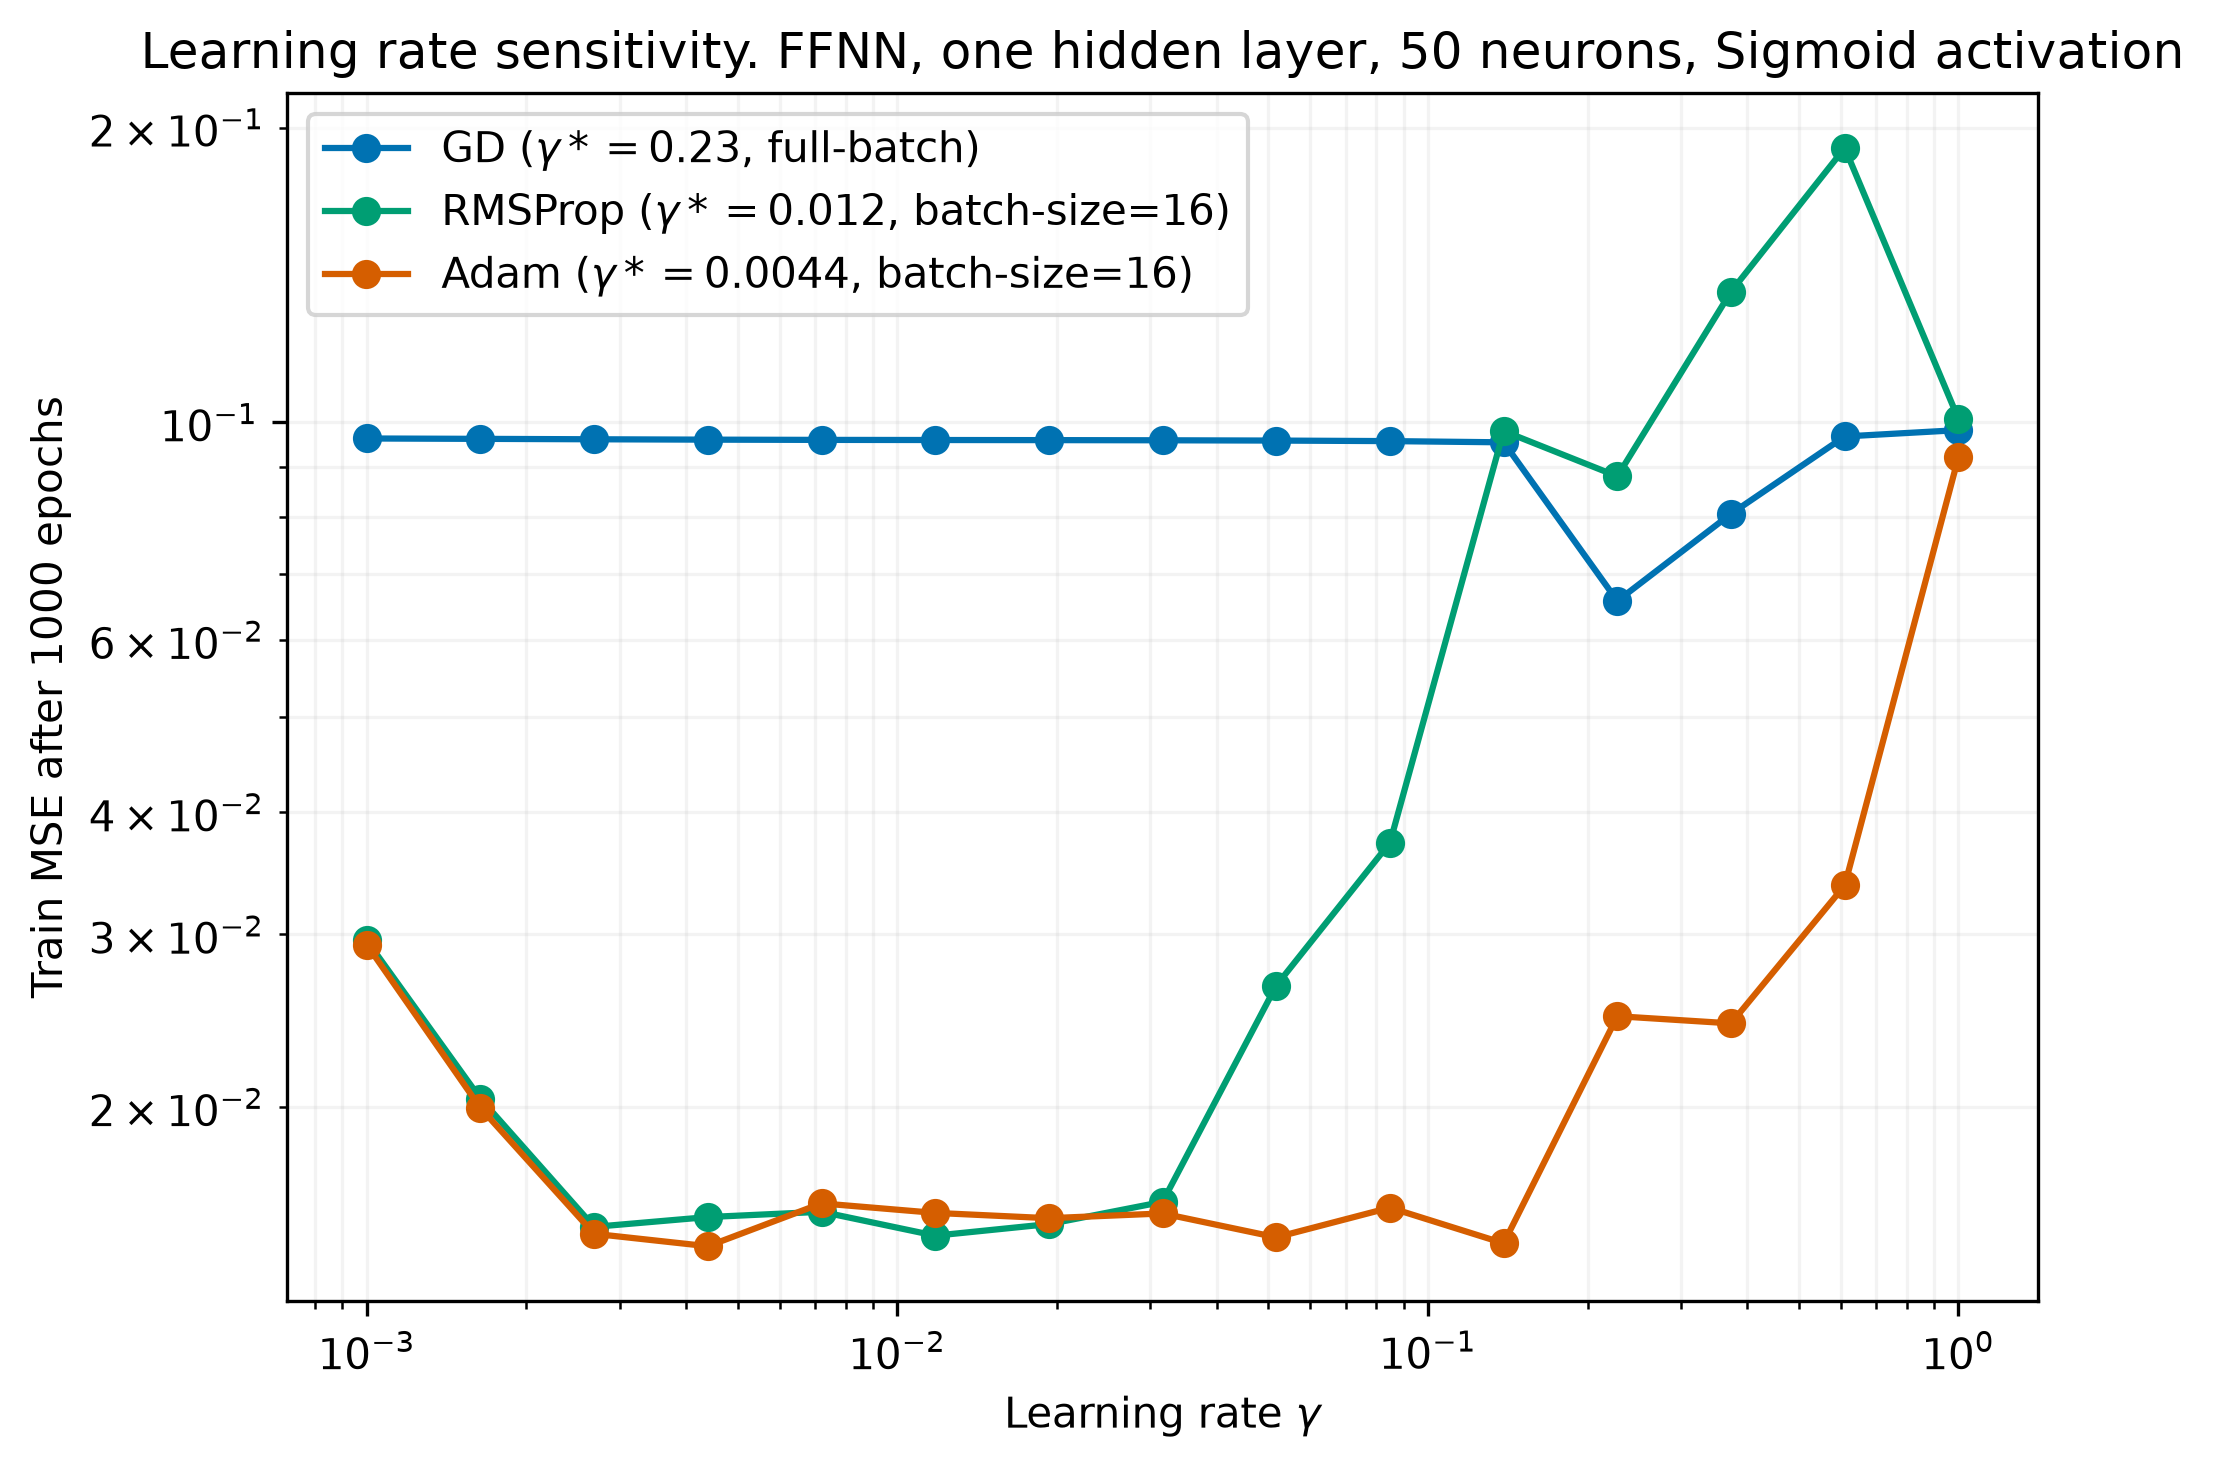

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, data in sweep_b_50.items():
    mse = data["final_mse"]
    batch_size = BATCH_SIZES_B[name]
    batch_size_label = "full-batch" if batch_size is None else f"batch-size={batch_size}"
    ax.plot(
        GAMMAS,
        np.where(np.isfinite(mse), mse, np.nan),
        color=OPTIMIZER_COLORS[name],
        marker="o",
        label=rf"{name} ($\gamma*={data['best_gamma']:.2g}$, {batch_size_label})",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(
    xlabel=r"Learning rate $\gamma$",
    ylabel=f"Train MSE after {EPOCHS_B} epochs",
    title="Learning rate sensitivity. FFNN, one hidden layer, 50 neurons, Sigmoid activation",
)
ax.grid(alpha=0.15, which="both")
ax.legend()
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_b_training_mse_gamma_50.pdf")
plt.show()

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_b_optimizer_convergence_50.pdf


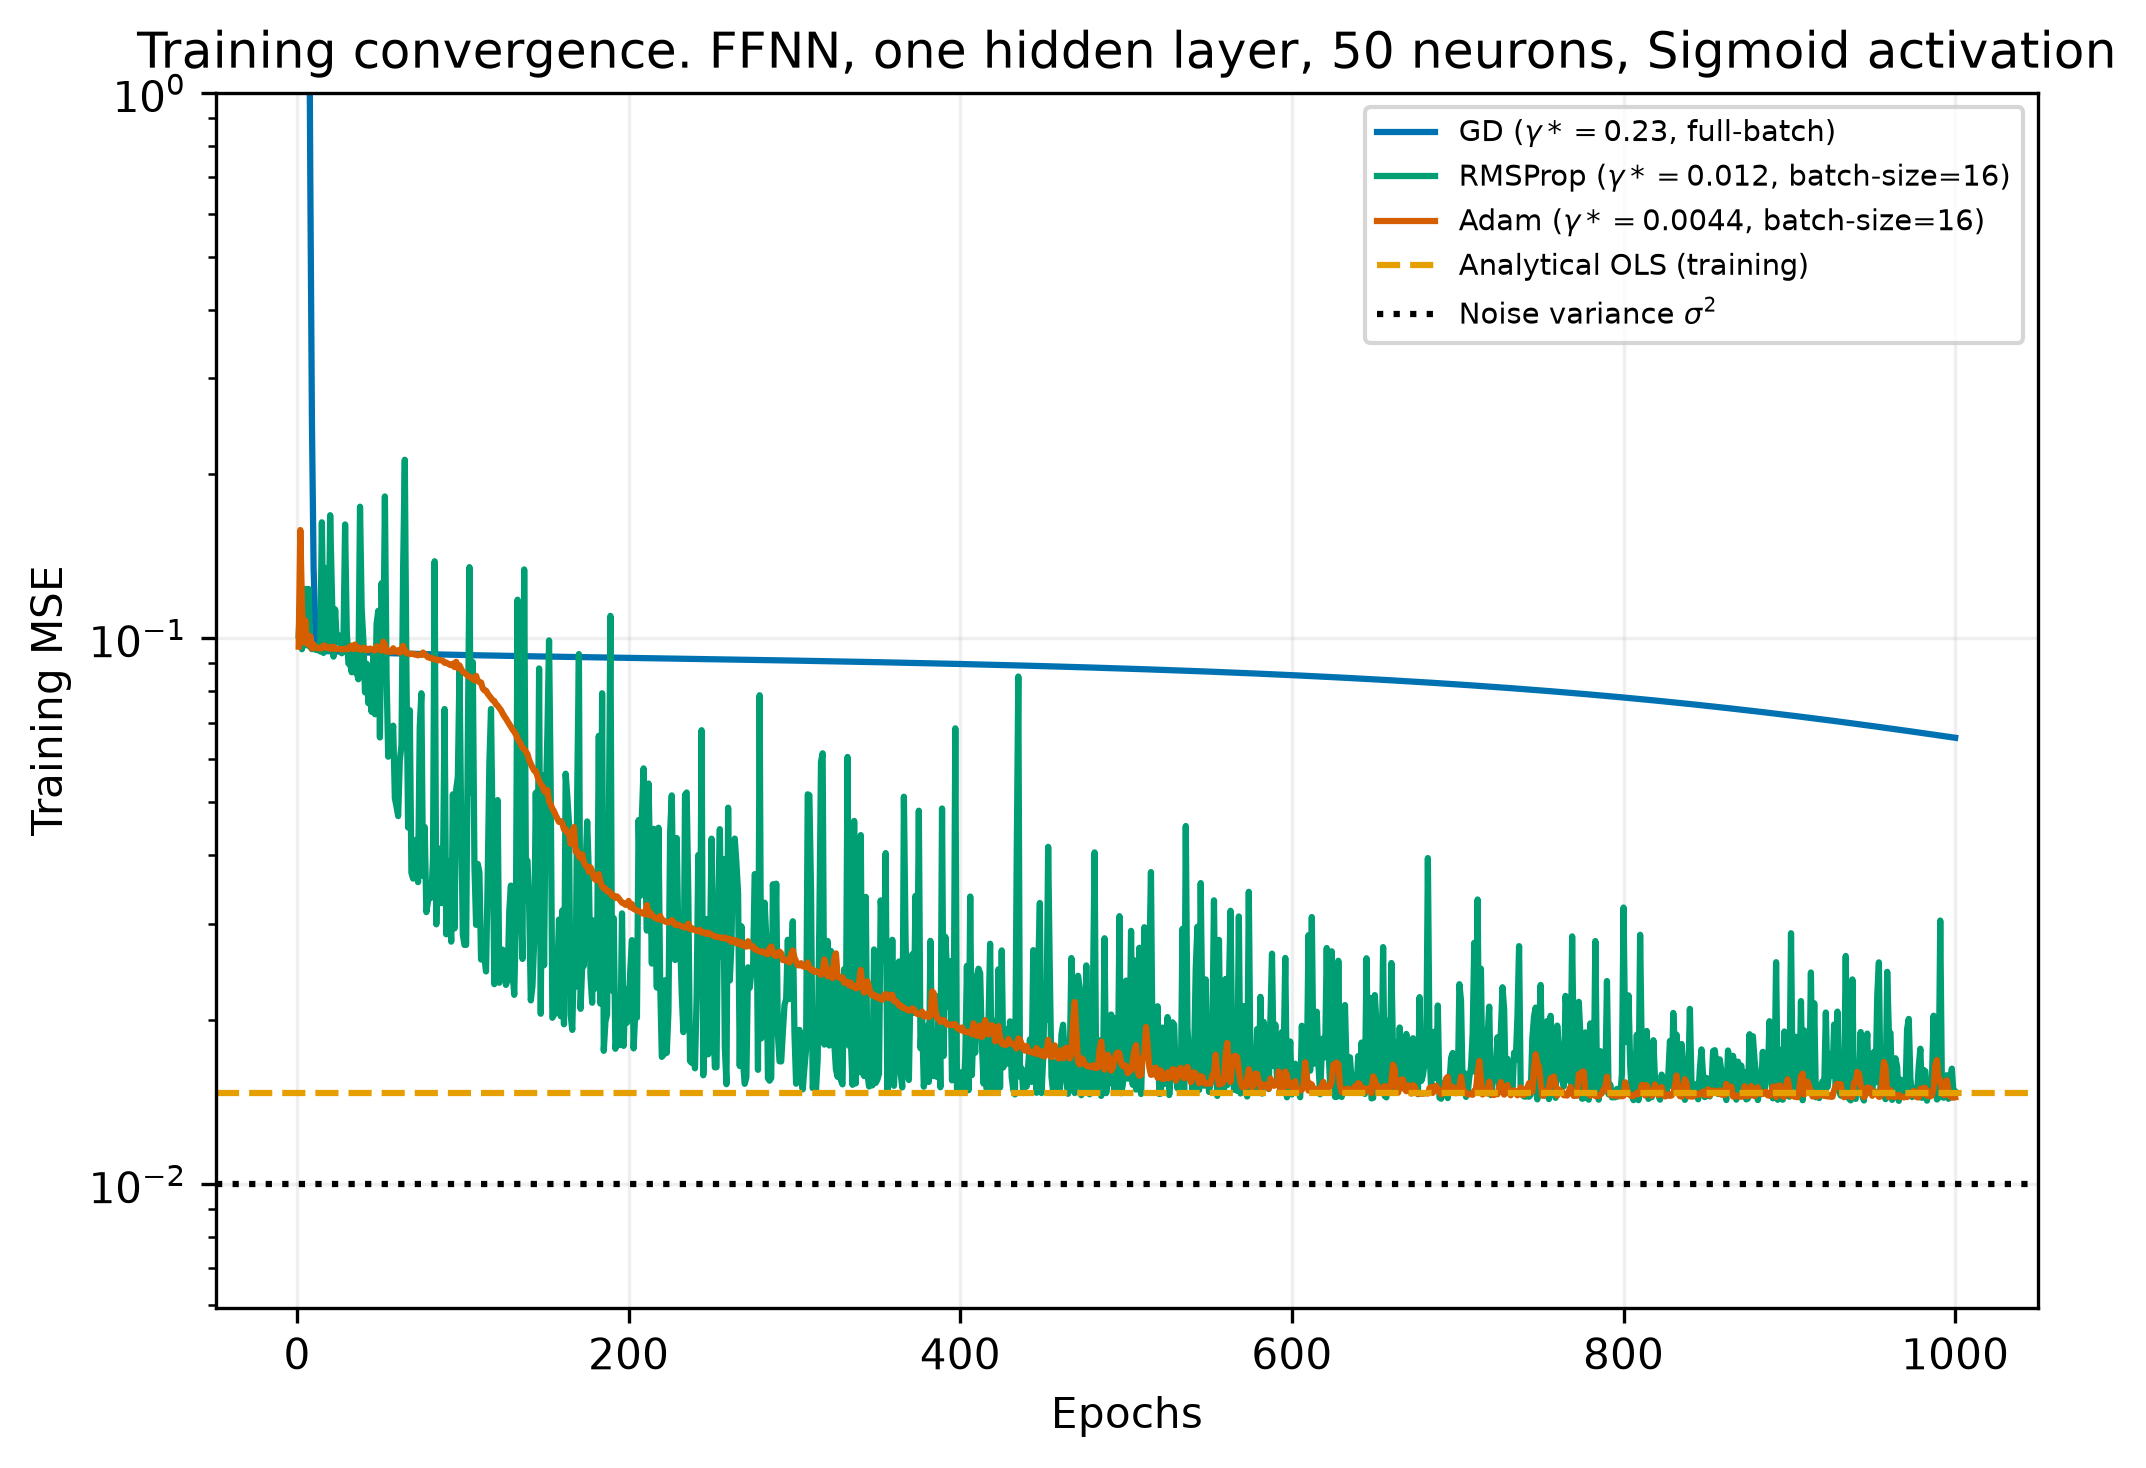

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, data in sweep_b_50.items():
    mse = data["train_mse"]
    batch_size = BATCH_SIZES_B[name]
    batch_size_label = "full-batch" if batch_size is None else f"batch-size={batch_size}"
    ax.plot(
        np.arange(1, len(mse) + 1),
        mse,
        color=OPTIMIZER_COLORS[name],
        linewidth=1.5,
        label=rf"{name} ($\gamma*={data['best_gamma']:.2g}$, {batch_size_label})",
    )

ax.axhline(
    result_b_50["Analytical OLS"]["MSE"],
    color=YELLOW,
    linestyle="--",
    label="Analytical OLS (training)",
)

ax.axhline(NOISE**2, color=BLACK, linestyle=":", label=r"Noise variance $\sigma^2$")

ax.set_yscale("log")
ax.set(
    xlabel="Epochs",
    ylabel="Training MSE",
    title="Training convergence. FFNN, one hidden layer, 50 neurons, Sigmoid activation",
)
ax.set_ylim(top=1e0)
ax.grid(alpha=0.2)
ax.legend(fontsize=7)
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_b_optimizer_convergence_50.pdf")
plt.show()

### **Part c):** Activation functions, depth and width

We are now asked to study the network architecture. We will use Adam with $\gamma=0.01$ and batch-size = 16 for this part.



In [70]:
DEPTHS = [1, 2, 3, 4]
WIDTHS = [30, 50, 100, 150, 300]

EPOCHS_C = 500
BATCH_SIZE_C = 16
N_SPLITS_C = 5  # five-fold cross-validation

In [73]:
from project2.scripts import part_c

result_c = part_c.run(
    x_train=x_train,
    y_train=y_train,
    depths=DEPTHS,
    widths=WIDTHS,
    gamma=0.01,
    epochs=EPOCHS_C,
    batch_size=BATCH_SIZE_C,
    n_splits=N_SPLITS_C,
    seed=SEED,
)

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_c_activations_cv.pdf


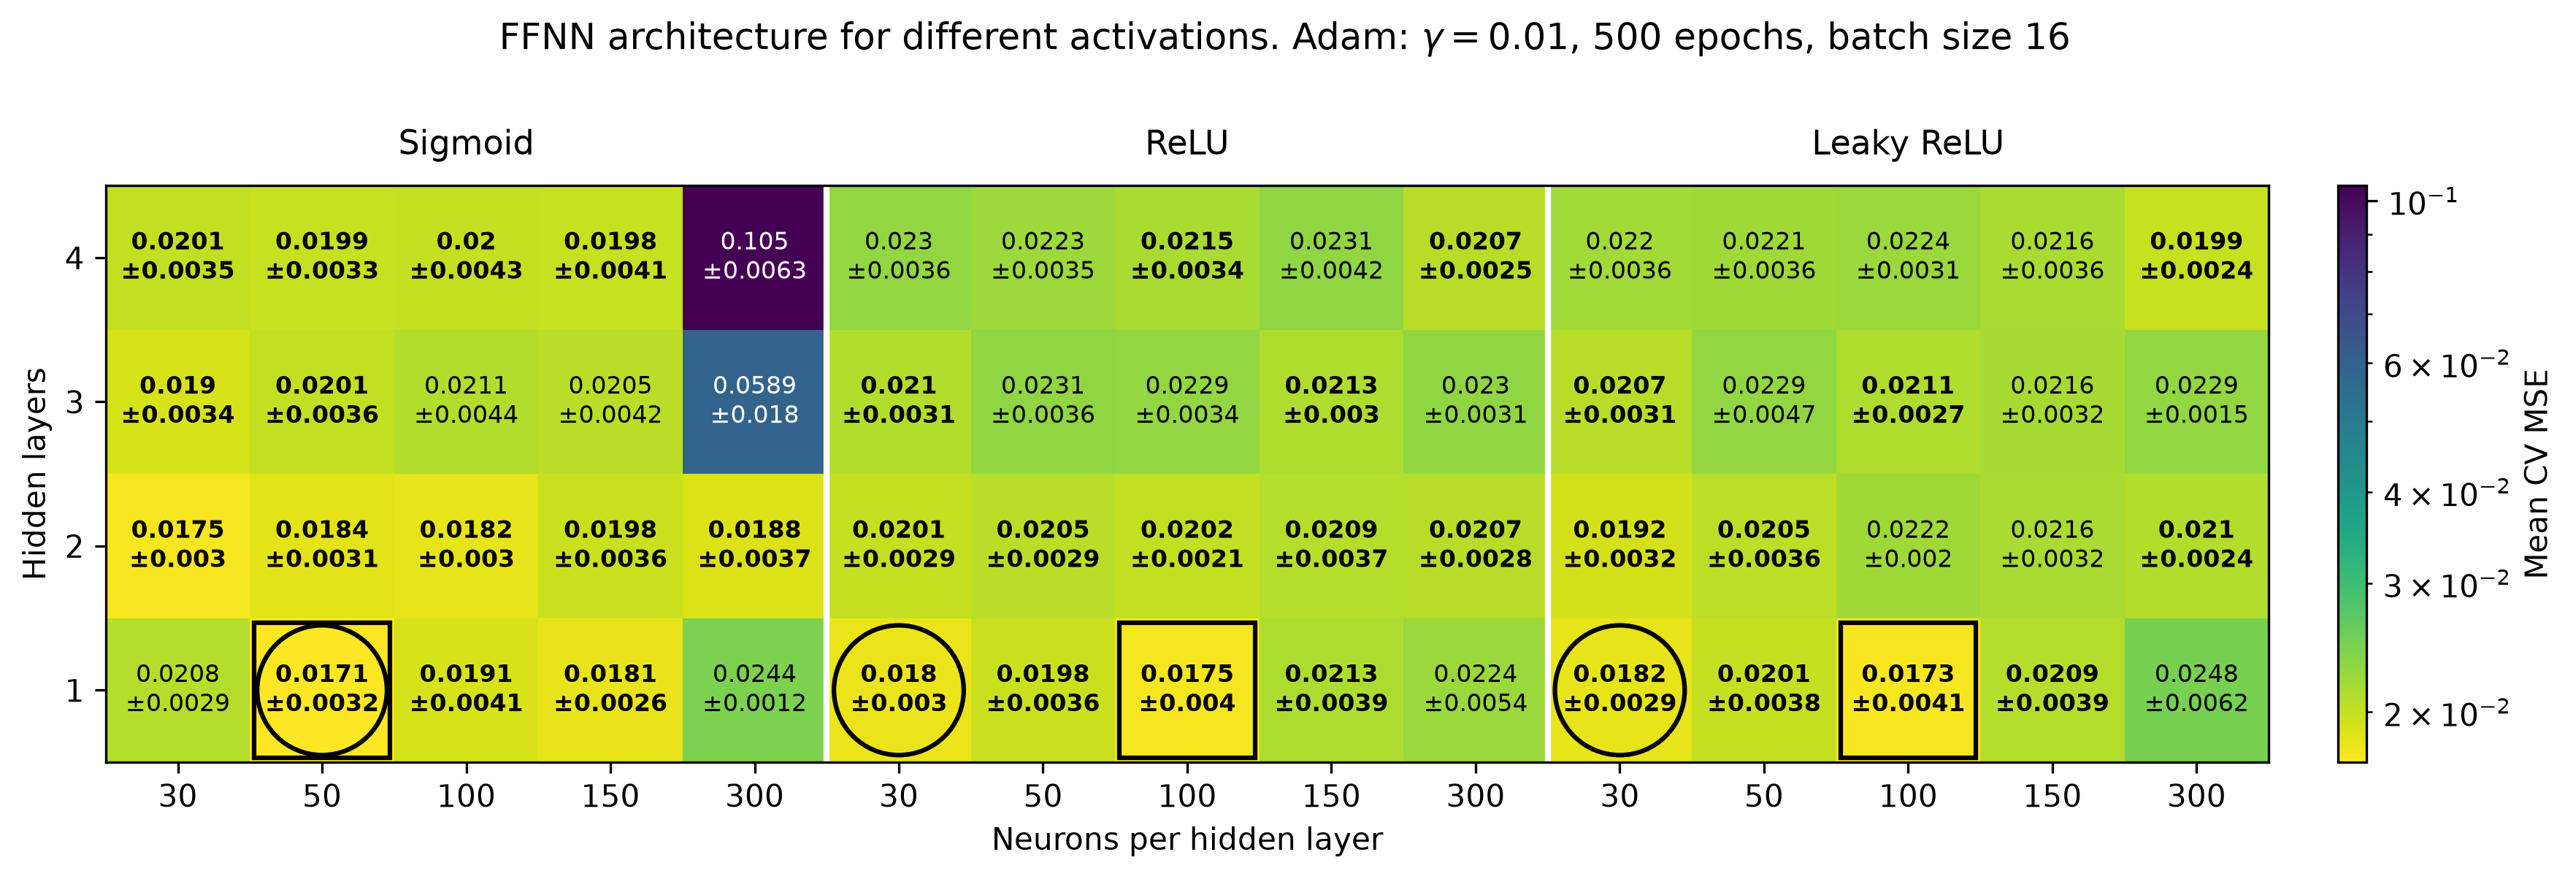

In [74]:
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse, Rectangle

"""
    LLM-assisted
    ------------
    Tool: ChatGPT (November 2026)
    Role: Plot activation heatmaps for cross-validation results.
    Modifications: Some titles and labels adjusted for clarity.
    Promt: Gave it part_c.py code and asked to plot heatmaps in one panel
"""

# Combine the activation heatmaps horizontally.
names = list(part_c.ACTIVATIONS)
n_widths = len(WIDTHS)

means = np.hstack(result_c["cv_mse"])
sd = np.hstack(result_c["cv_se"])
within = np.hstack([result_c["selection"][name]["within"] for name in names])

# Common colour scale.
finite = means[np.isfinite(means) & (means > 0)]
norm = LogNorm(
    vmin=finite.min(),
    vmax=max(finite.max(), finite.min() * 1.01),
)

cmap = plt.get_cmap("viridis_r").copy()
fig, ax = plt.subplots(figsize=(12, 4))

im = ax.imshow(np.ma.masked_invalid(means), origin="lower", aspect="equal", cmap=cmap, norm=norm)

ax.set_xticks(
    range(means.shape[1]),
    labels=[str(width) for _ in names for width in WIDTHS],
)
ax.set_yticks(range(len(DEPTHS)), labels=DEPTHS)
ax.set(xlabel="Neurons per hidden layer", ylabel="Hidden layers")

# Cell annotations: mean ± fold SD.
for row, col in np.ndindex(means.shape):
    mean = means[row, col]
    deviation = sd[row, col]

    text = f"{mean:.3g}\n±{deviation:.2g}" if np.isfinite(mean) else "—"
    color = "white" if norm(mean) > 0.5 else "black"

    ax.text(
        col,
        row,
        text,
        ha="center",
        va="center",
        fontsize=8,
        color=color,
        fontweight="bold" if within[row, col] else "normal",
    )

# Separate headings and selection markers for each activation.
for a, name in enumerate(names):
    offset = a * n_widths

    ax.text(
        offset + (n_widths - 1) / 2,
        1.04,
        name,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=11,
    )

    if a > 0:
        ax.axvline(offset - 0.5, color="white", linewidth=2)

    choice = result_c["selection"][name]

    # Square: lowest CV MSE for this activation.
    row, col = choice["minimum"]
    col += offset
    edge = "white" if norm(means[row, col]) > 0.5 else BLACK

    ax.add_patch(
        Rectangle((col - 0.47, row - 0.47), 0.94, 0.94, fill=False, edgecolor=edge, linewidth=1.5)
    )

    # Circle: one-SE-selected model for this activation.
    row, col = choice["selected"]
    col += offset
    edge = "white" if norm(means[row, col]) > 0.5 else BLACK

    ax.add_patch(Ellipse((col, row), 0.9, 0.9, fill=False, edgecolor=edge, linewidth=1.5))

# Single shared colourbar on the far right.
fig.colorbar(im, ax=ax, location="right", fraction=0.025, pad=0.03, label="Mean CV MSE")

fig.suptitle(
    rf"FFNN architecture for different activations. Adam: $\gamma=0.01$, {EPOCHS_C} epochs, "
    f"batch size {BATCH_SIZE_C}",
    fontsize=12,
)

fig.tight_layout(rect=(0, 0.08, 1, 0.91))
save_figure(fig, FIGURES_DIR, "part_c_activations_cv.pdf")
plt.show()

### **Part d):** Regularization with L1 and L2 penalties


We will for the rest of the project use Adam as the optimizer. It is, as we noted in **b)**, the least sensitive and usually the fastest and most stable, which we also experienced in the experiments of project 1.

We first perform an extensive grid search over regularization strengths ($\lambda$), learning rates ($\gamma$), and selected network architectures.

In [7]:
from project2.scripts import part_d

ARCHITECTURES_D = [(50,), (100, 100), (150,), (300, 300)]
GAMMAS_D = np.array([0.003, 0.01, 0.05, 0.1])
LAMBDAS_D = np.array([1e-5, 1e-4, 1e-3, 1e-1])

EPOCHS_D = 500
BATCH_SIZE_D = 16
N_SPLITS_D = 5

result_d = part_d.run(
    x_train=x_train,
    y_train=y_train,
    architectures=ARCHITECTURES_D,
    gammas=GAMMAS_D,
    lambdas=LAMBDAS_D,
    epochs=EPOCHS_D,
    batch_size=BATCH_SIZE_D,
    n_splits=N_SPLITS_D,
    seed=SEED,
)

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_d_l1_cv.pdf


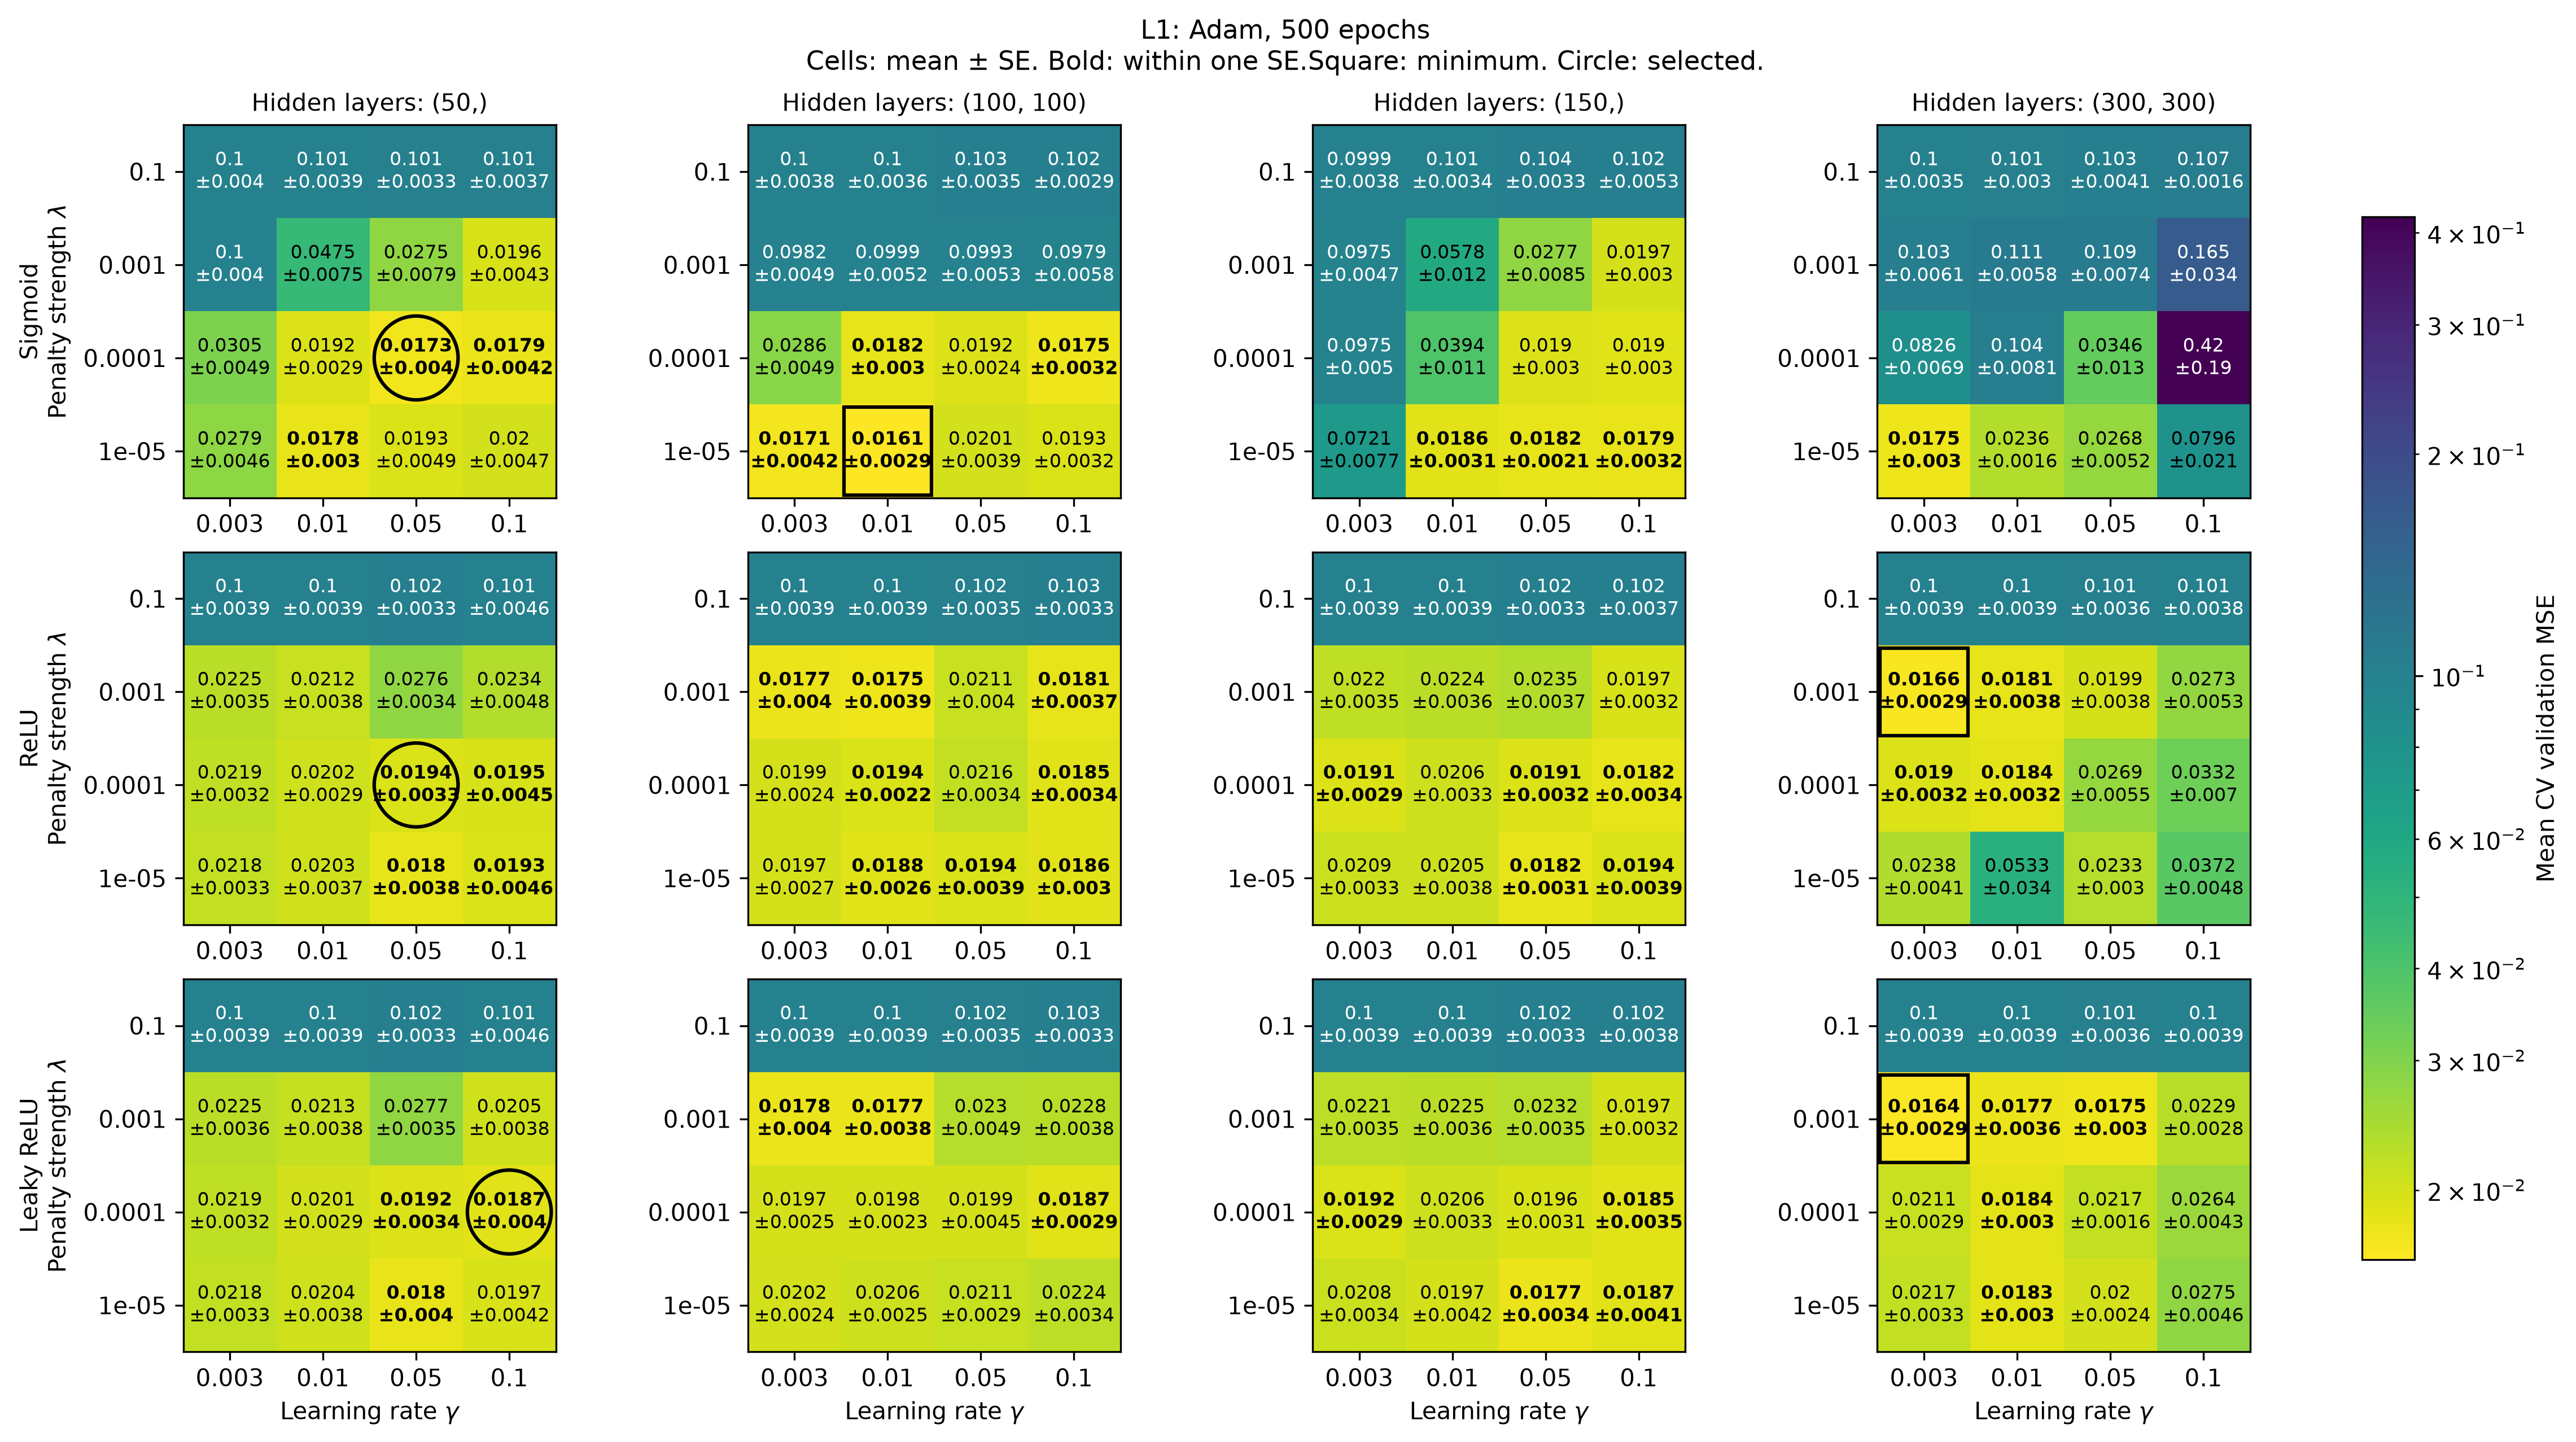

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_d_l2_cv.pdf


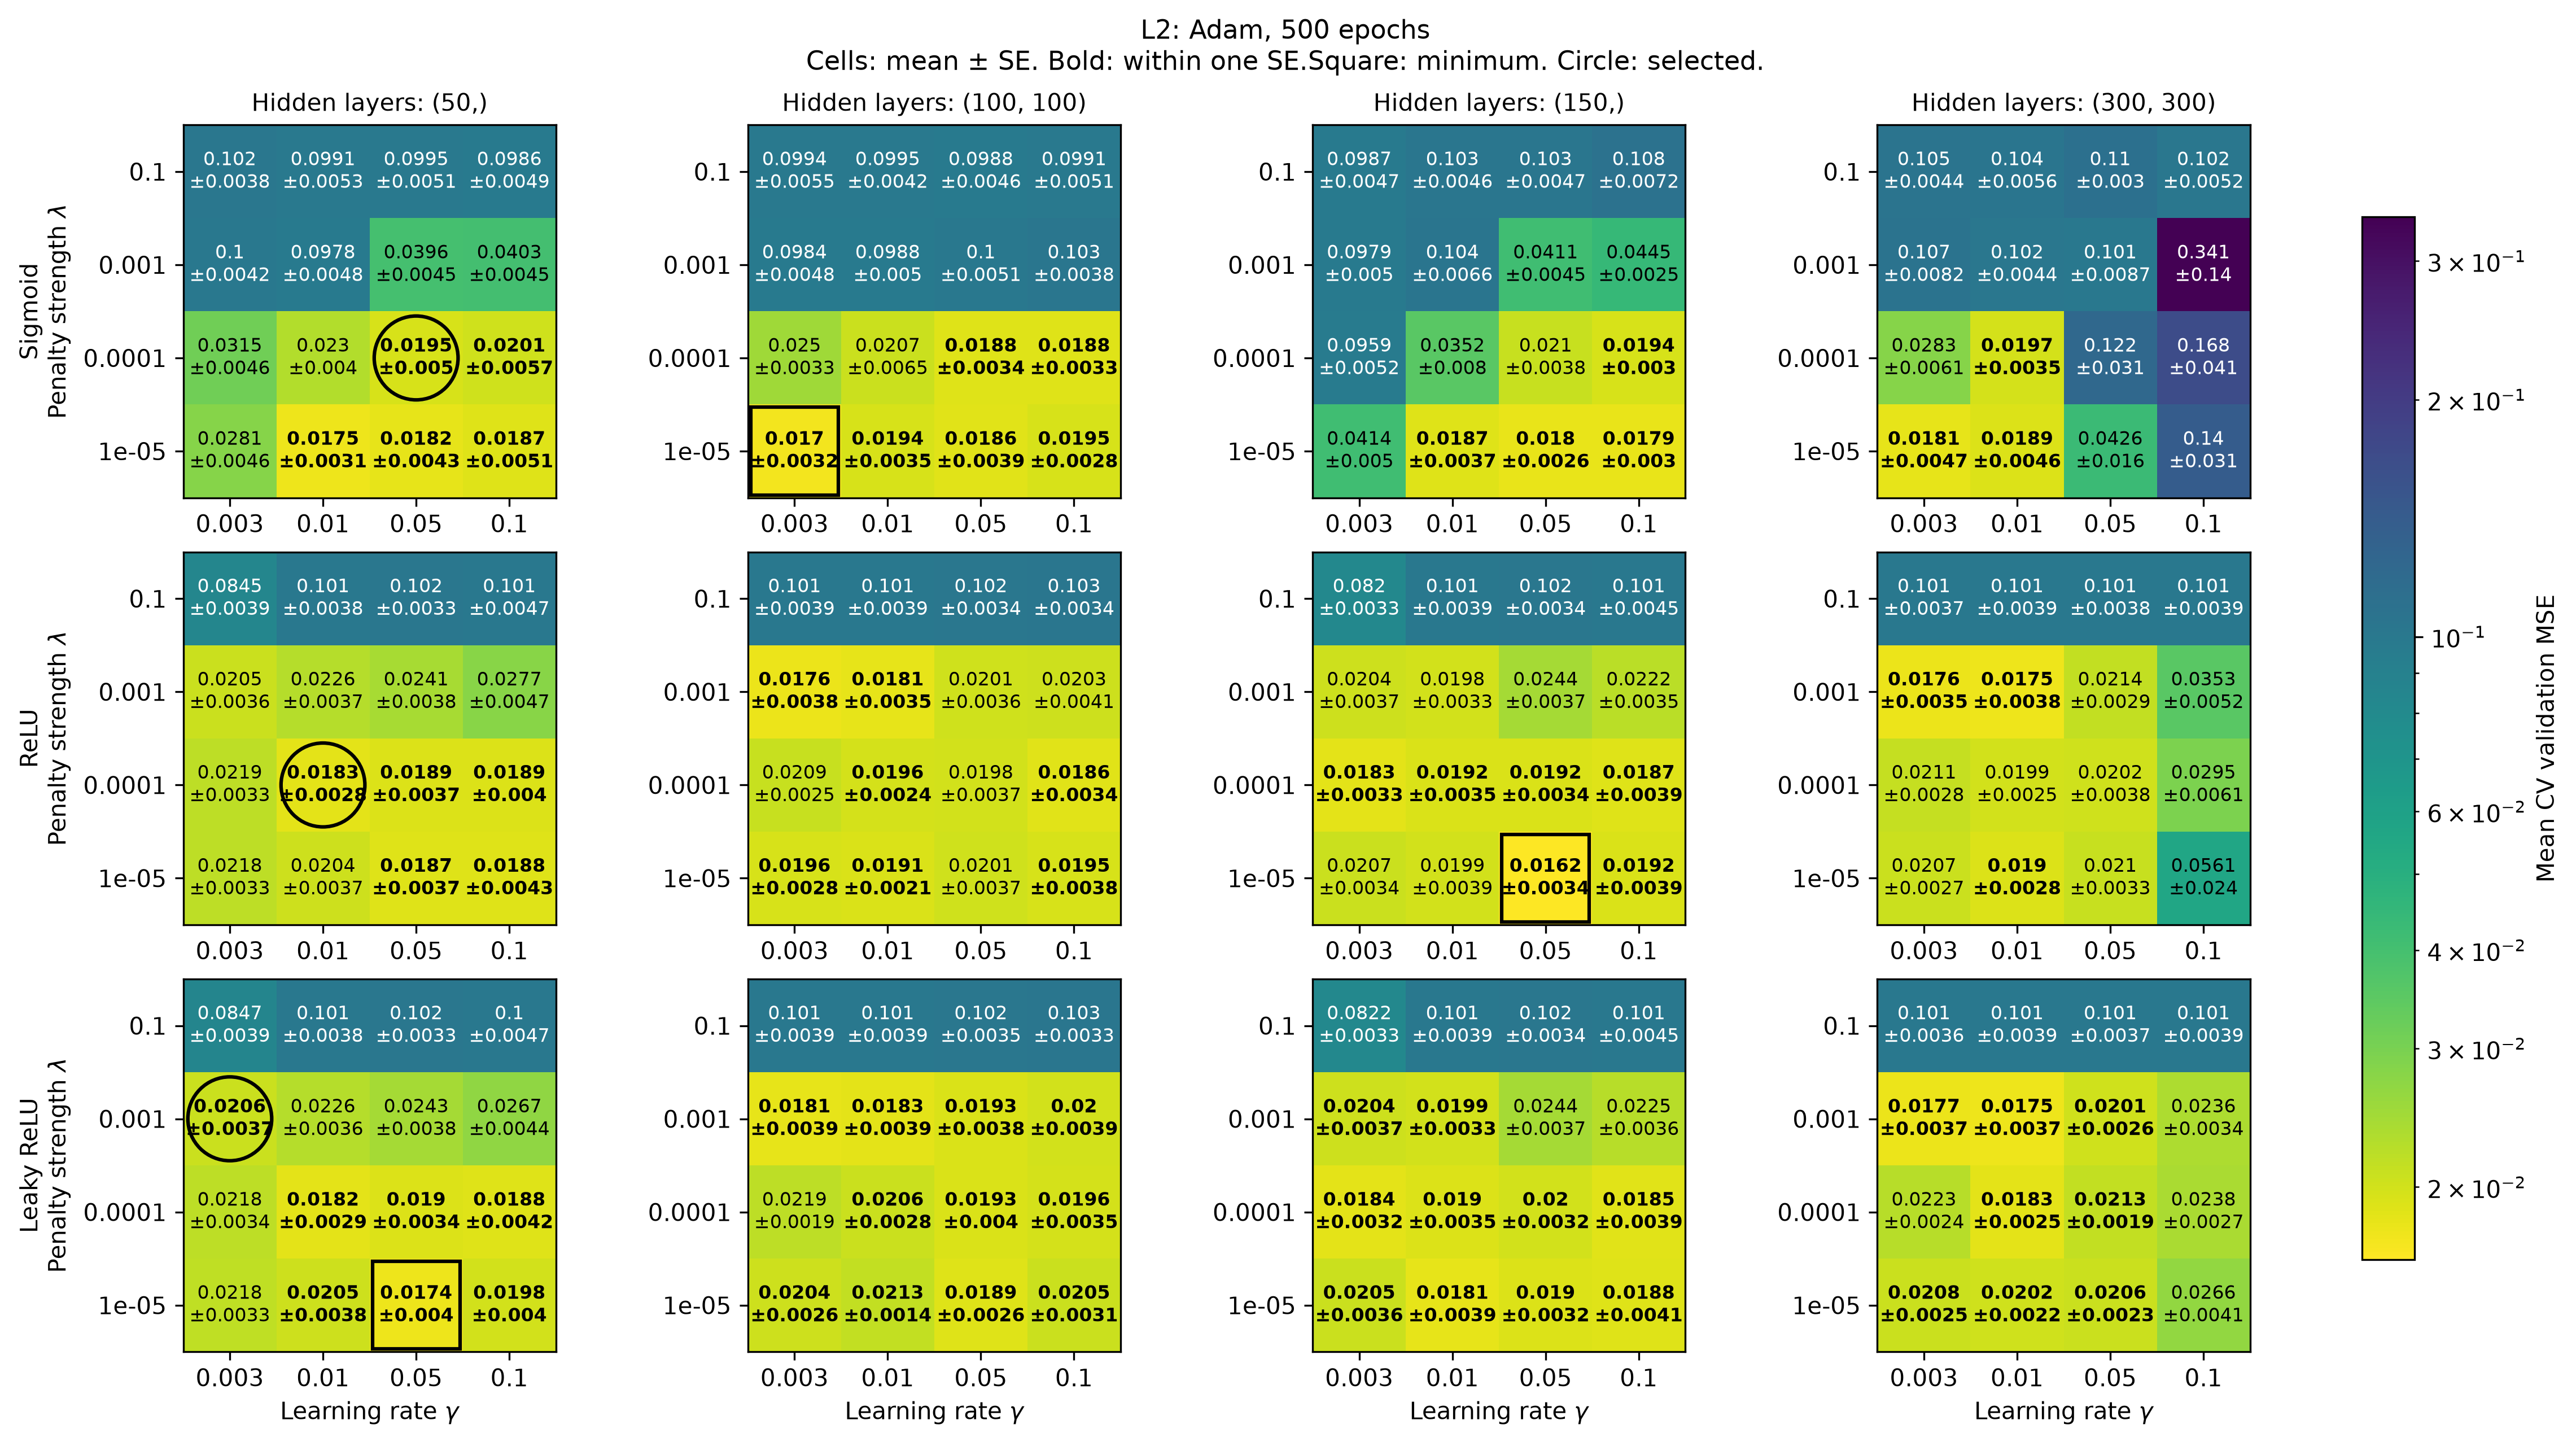

In [8]:
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse, Rectangle

"""
    LLM-assisted
    ------------
    Tool: ChatGPT (November 2026)
    Role: Plot heatmaps for cross-validation results for L1 and L2.
    Modifications: Some titles and labels adjusted for clarity.
    Also, activation in rows instead of columns.
    Promt: Gave it part_d.py code and asked to plot heatmaps. One for L1 and one for L2.
"""

names = list(part_d.ACTIVATIONS)

for penalty in ("L1", "L2"):
    values = np.concatenate(
        [result_d["results"][name][penalty]["cv_mse"].ravel() for name in names]
    )
    finite = values[np.isfinite(values) & (values > 0)]

    norm = LogNorm(vmin=finite.min(), vmax=max(finite.max(), finite.min() * 1.01))
    cmap = plt.get_cmap("viridis_r").copy()
    cmap.set_bad("#eeeeee")

    fig, axes = plt.subplots(
        len(names),
        len(ARCHITECTURES_D),
        figsize=(3.8 * len(ARCHITECTURES_D), 2.8 * len(names)),
        squeeze=False,
        layout="constrained",
    )

    for row, name in enumerate(names):
        data = result_d["results"][name][penalty]
        choice = data["selection"]

        for a, hidden in enumerate(ARCHITECTURES_D):
            ax = axes[row, a]
            means = data["cv_mse"][a]
            se = data["cv_se"][a]
            within = choice["within"][a]

            im = ax.imshow(
                np.ma.masked_invalid(means), origin="lower", aspect="equal", cmap=cmap, norm=norm
            )

            ax.set_xticks(range(len(GAMMAS_D)), labels=[f"{g:g}" for g in GAMMAS_D])
            ax.set_yticks(range(len(LAMBDAS_D)), labels=[f"{l:g}" for l in LAMBDAS_D])
            if row == 0:
                ax.set_title(f"Hidden layers: {hidden}", fontsize=10)

            if row == len(names) - 1:
                ax.set_xlabel(r"Learning rate $\gamma$")

            if a == 0:
                ax.set_ylabel(f"{name}\n" r"Penalty strength $\lambda$")

            for l, g in np.ndindex(means.shape):
                mean = means[l, g]
                text = f"{mean:.3g}\n±{se[l, g]:.2g}" if np.isfinite(mean) else "—"
                color = "white" if np.isfinite(mean) and norm(mean) > 0.5 else BLACK

                ax.text(
                    g,
                    l,
                    text,
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=color,
                    fontweight="bold" if within[l, g] else "normal",
                )

            # Square: minimum CV MSE for this activation and penalty.
            a_min, l_min, g_min = choice["minimum"]
            if a == a_min:
                edge = "white" if norm(means[l_min, g_min]) > 0.5 else BLACK
                ax.add_patch(
                    Rectangle(
                        (g_min - 0.47, l_min - 0.47),
                        0.94,
                        0.94,
                        fill=False,
                        edgecolor=edge,
                        linewidth=1.5,
                    )
                )

            # Circle: one-SE selection for this activation and penalty.
            a_sel, l_sel, g_sel = choice["selected"]
            if a == a_sel:
                edge = "white" if norm(means[l_sel, g_sel]) > 0.5 else BLACK
                ax.add_patch(
                    Ellipse(
                        (g_sel, l_sel),
                        0.9,
                        0.9,
                        fill=False,
                        edgecolor=edge,
                        linewidth=1.5,
                    )
                )

    fig.colorbar(
        im, ax=axes.ravel().tolist(), location="right", shrink=0.85, label="Mean CV validation MSE"
    )
    fig.suptitle(
        f"{penalty}: Adam, {EPOCHS_D} epochs\n"
        "Cells: mean ± SE. Bold: within one SE.Square: minimum. Circle: selected.",
        fontsize=11,
    )

    save_figure(fig, FIGURES_DIR, f"part_d_{penalty.lower()}_cv.pdf")
    plt.show()

We now look at the the selected architectures from above for each activation.

In [9]:
from project2.utils import save_wide_table

"""
    LLM-assisted
    ------------
    Tool: ChatGPT (November 2026)
    Role: Save tables of selected models for each activation and penalty.
    Modifications: Caption and simplifications.
    Promt: Gave it part_d.py code and asked to save the table, using our table_saving functions.
"""

selection_rows = []
for activation, penalties in result_d["results"].items():
    for penalty, data in penalties.items():
        config = data["selected"]

        selection_rows.append(
            {
                "Penalty": penalty,
                "Activation": activation,
                "Architecture": str(config["hidden_sizes"]),
                "Parameters": config["n_parameters"],
                r"$\gamma$": config["gamma"],
                r"$\lambda$": config["lambda"],
                "CV MSE": config["cv_mse"],
                "CV SE": config["cv_se"],
            }
        )

selection_table_d = (
    pd.DataFrame(selection_rows).sort_values("Penalty", kind="stable").reset_index(drop=True)
)

winners_d = [
    row["Activation"] == result_d["best"][row["Penalty"]]["activation"]
    for _, row in selection_table_d.iterrows()
]

display(
    selection_table_d.style.apply(
        lambda row: ["font-weight: bold" if winners_d[row.name] else ""] * len(row),
        axis=1,
    )
)

# Preserve the bold rows in the LaTeX export.
latex_selection_d = selection_table_d.astype(object)

for i in range(len(latex_selection_d)):
    for column in latex_selection_d:
        value = selection_table_d.loc[i, column]
        text = f"{value:.4g}" if isinstance(value, (float, np.floating)) else str(value)

        if winners_d[i]:
            text = r"\textbf{" + text + "}"

        latex_selection_d.loc[i, column] = text

save_wide_table(
    latex_selection_d,
    TABLES_DIR,
    "part_d_selected_models.tex",
    caption=(
        "One-standard-error selections for each activation and penalty. "
        "Bold rows have the lowest CV MSE among the three "
        "activation-specific selections for each penalty. "
        "Scores are mean validation MSE and SE."
    ),
    label="part_d_selected_models",
)

,Penalty,Activation,Architecture,Parameters,$\gamma$,$\lambda$,CV MSE,CV SE
0,L1,Sigmoid,"(50,)",151,0.050000,0.000100,0.017294,0.003953
1,L1,ReLU,"(50,)",151,0.050000,0.000100,0.019367,0.003305
2,L1,Leaky ReLU,"(50,)",151,0.100000,0.000100,0.018659,0.003992
3,L2,Sigmoid,"(50,)",151,0.050000,0.000100,0.019483,0.004988
4,L2,ReLU,"(50,)",151,0.010000,0.000100,0.018251,0.002843
5,L2,Leaky ReLU,"(50,)",151,0.003000,0.001000,0.020631,0.003652


Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/report/tables/part_d_selected_models.tex
Use in main.tex: \input{tables/part_d_selected_models.tex}


PosixPath('/home/hmmorad/school/STK/fys-stk3155/projects/project2/report/tables/part_d_selected_models.tex')

In [ ]:
POLYNOMIAL_SETTINGS = {
    "OLS": (OLS_BEST_DEGREE, 0.0),
    "Ridge": (RIDGE_BEST_DEGREE, RIDGE_BEST_LAMBDA),
    "Lasso": (LASSO_BEST_DEGREE, LASSO_BEST_LAMBDA),
}

comparison_d = part_d.fit_comparison(
    x_train=x_train,
    y_train=y_train,
    x_grid=x_grid,
    best=result_d["best"],
    polynomial_settings=POLYNOMIAL_SETTINGS,
    epochs=EPOCHS_D,
    batch_size=BATCH_SIZE_D,
    seed=SEED,
)

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_d_runge_comparison.pdf


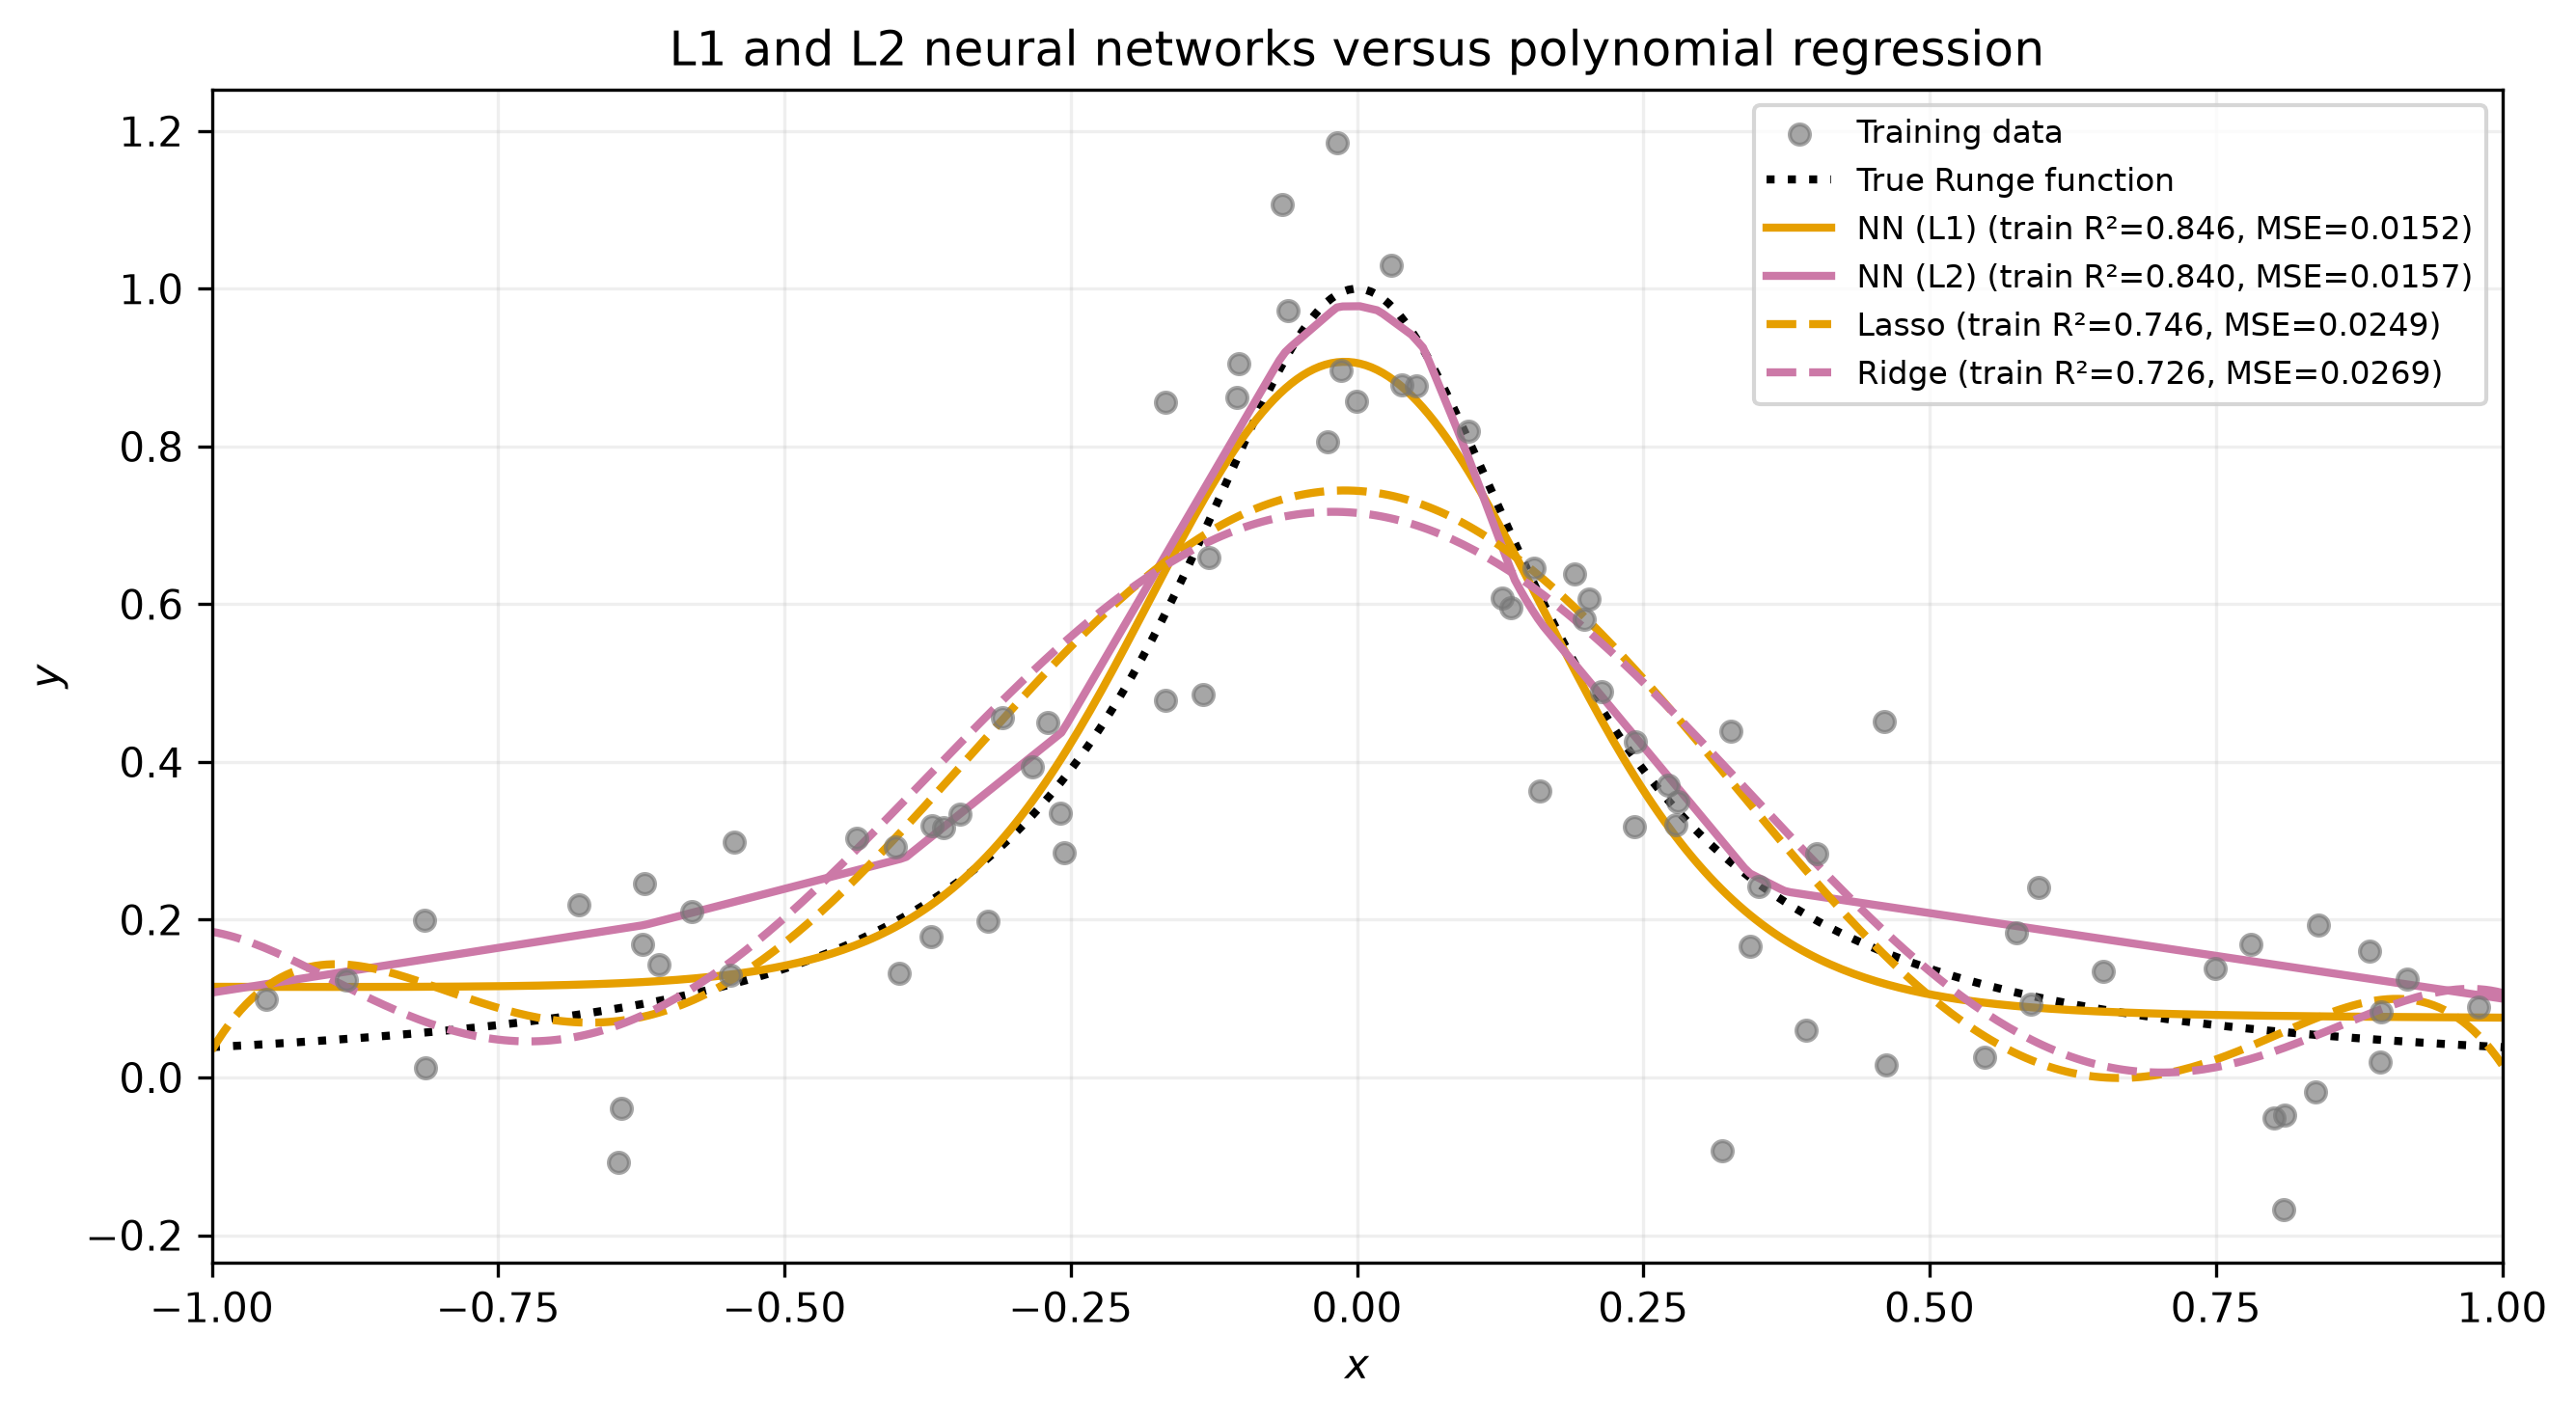

In [14]:
model_colors_d = {
    "NN (L1)": L1_COLOR,
    "NN (L2)": L2_COLOR,
    "Lasso": L1_COLOR,
    "Ridge": L2_COLOR,
}

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    x_train.ravel(),
    y_train.ravel(),
    color=TRAIN_COLOR,
    s=25,
    alpha=0.65,
    label="Training data",
    zorder=3,
)

ax.plot(
    x_grid.ravel(),
    1 / (1 + 25 * x_grid.ravel() ** 2),
    color=BLACK,
    linestyle=":",
    linewidth=2,
    label="True Runge function",
)

for name, color in model_colors_d.items():
    model = comparison_d["models"][name]

    ax.plot(
        x_grid.ravel(),
        model["grid_prediction"],
        color=color,
        linestyle="--" if name in ("Ridge", "Lasso") else "-",
        linewidth=2,
        label=(f"{name} (train R²={model['train_r2']:.3f}, MSE={model['MSE']:.4f})"),
    )

ax.set(
    xlabel="$x$",
    ylabel="$y$",
    xlim=(-1, 1),
    title="L1 and L2 neural networks versus polynomial regression",
)
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_d_runge_comparison.pdf")
plt.show()

#### **Final comparison**

In [75]:
from project2.utils import save_wide_table

# Previously computed in Project 1 on the same training/test split. Same seed.
# See final table in Project1_results.ipynb or in the project1 report.
PROJECT1_CV = {
    "OLS": (0.023505, 0.004850),
    "Ridge": (0.028946, 0.004678),
    "Lasso": (0.027039, 0.004996),
}

choice_c = min(
    result_c["selected"].values(),
    key=lambda config: config["cv_mse"],
)

comparison_d["network_fits"]["none"] = part_d.fit_selected(
    x_train,
    y_train,
    {**choice_c, "penalty": "none", "lambda": 0.0},
    epochs=EPOCHS_C,
    batch_size=BATCH_SIZE_C,
    seed=SEED,
)

regression_table = pd.DataFrame(
    part_d.final_comparison(
        x_test=x_test, y_test=y_test, comparison=comparison_d, project1_cv=PROJECT1_CV
    )
)
display(regression_table)

save_wide_table(
    regression_table,
    TABLES_DIR,
    "part_d_final_comparison.tex",
    caption=(
        "Final regression comparison. All models are fitted on "
        "80 training observations and evaluated on the same "
        "20 held-out test observations after selection. "
        "Polynomial CV scores are reused from Project 1. "
        "MSE excludes regularization penalties."
    ),
    label="part_d_final_comparison",
)

,Model,Parameters,CV MSE,CV SE,Test MSE,Test R2
0,NN (L1),151,0.017294,0.003953,0.013346,0.892442
1,NN (L2),151,0.018251,0.002843,0.016606,0.866170
2,NN (none),151,0.017068,0.003194,0.011869,0.904343
3,OLS,11,0.023505,0.004850,0.037019,0.701663
4,Ridge,7,0.028946,0.004678,0.031527,0.745922
5,Lasso,7,0.027039,0.004996,0.023048,0.814256


Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/report/tables/part_d_final_comparison.tex
Use in main.tex: \input{tables/part_d_final_comparison.tex}


PosixPath('/home/hmmorad/school/STK/fys-stk3155/projects/project2/report/tables/part_d_final_comparison.tex')

### **Part e):** Classification with MNIST


**LLM-assisted: We have used ChatGPT to generate all the plots below**.

- Tool: ChatGPT (November 2026)
- Role: Helped with generating the plots
- Modifications: Small adjustments to fit our implementation.
- Promt: Explained what figures we wanted to plot, and gave the code from part_e.py



In [ ]:
from project2.utils.encoding import one_hot
from matplotlib.patches import Ellipse, Rectangle


mnist_data = np.load(PROJECT_ROOT / "datasets" / "mnist.npz")

X_all_e = mnist_data["x_train"].reshape(-1, 784).astype(np.float32)
X_all_e /= 255.0
y_all_e = mnist_data["y_train"]

images_test_e = mnist_data["x_test"]
X_test_e = images_test_e.reshape(-1, 784).astype(np.float32)
X_test_e /= 255.0
y_test_e = mnist_data["y_test"]

mnist_data.close()

Y_all_e = one_hot(y_all_e)

train_idx_e, val_idx_e = train_test_split(
    np.arange(len(y_all_e)), test_size=10000, stratify=y_all_e, random_state=SEED
)

X_train_e = X_all_e[train_idx_e]
X_val_e = X_all_e[val_idx_e]
Y_train_e = Y_all_e[train_idx_e]
Y_val_e = Y_all_e[val_idx_e]

print("Fitting:", X_train_e.shape, Y_train_e.shape)
print("Validation:", X_val_e.shape, Y_val_e.shape)
print("Test:", X_test_e.shape, y_test_e.shape)

Fitting: (50000, 784) (50000, 10)
Validation: (10000, 784) (10000, 10)
Test: (10000, 784) (10000,)


In [8]:
BATCH_SIZE_E = 1064
SCREEN_EPOCHS_E = 10
LONG_EPOCHS_E = 30

ARCHITECTURES_E = [(), (50,), (100,), (100, 100), (200, 200)]
GAMMAS_E = [1e-4, 1e-3, 1e-2]
LAMBDAS_E = [1e-5, 1e-4]


In [9]:
from project2.scripts import part_e

configs_e = [
    {"hidden_sizes": hidden, "activation": "ReLU", "gamma": gamma}
    for hidden in ARCHITECTURES_E
    for gamma in GAMMAS_E
]

screen_e = part_e.run_search(
    X_train_e,
    Y_train_e,
    X_val_e,
    Y_val_e,
    configs_e,
    epochs=SCREEN_EPOCHS_E,
    batch_size=BATCH_SIZE_E,
    seed=SEED,
)

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_e_screening.pdf


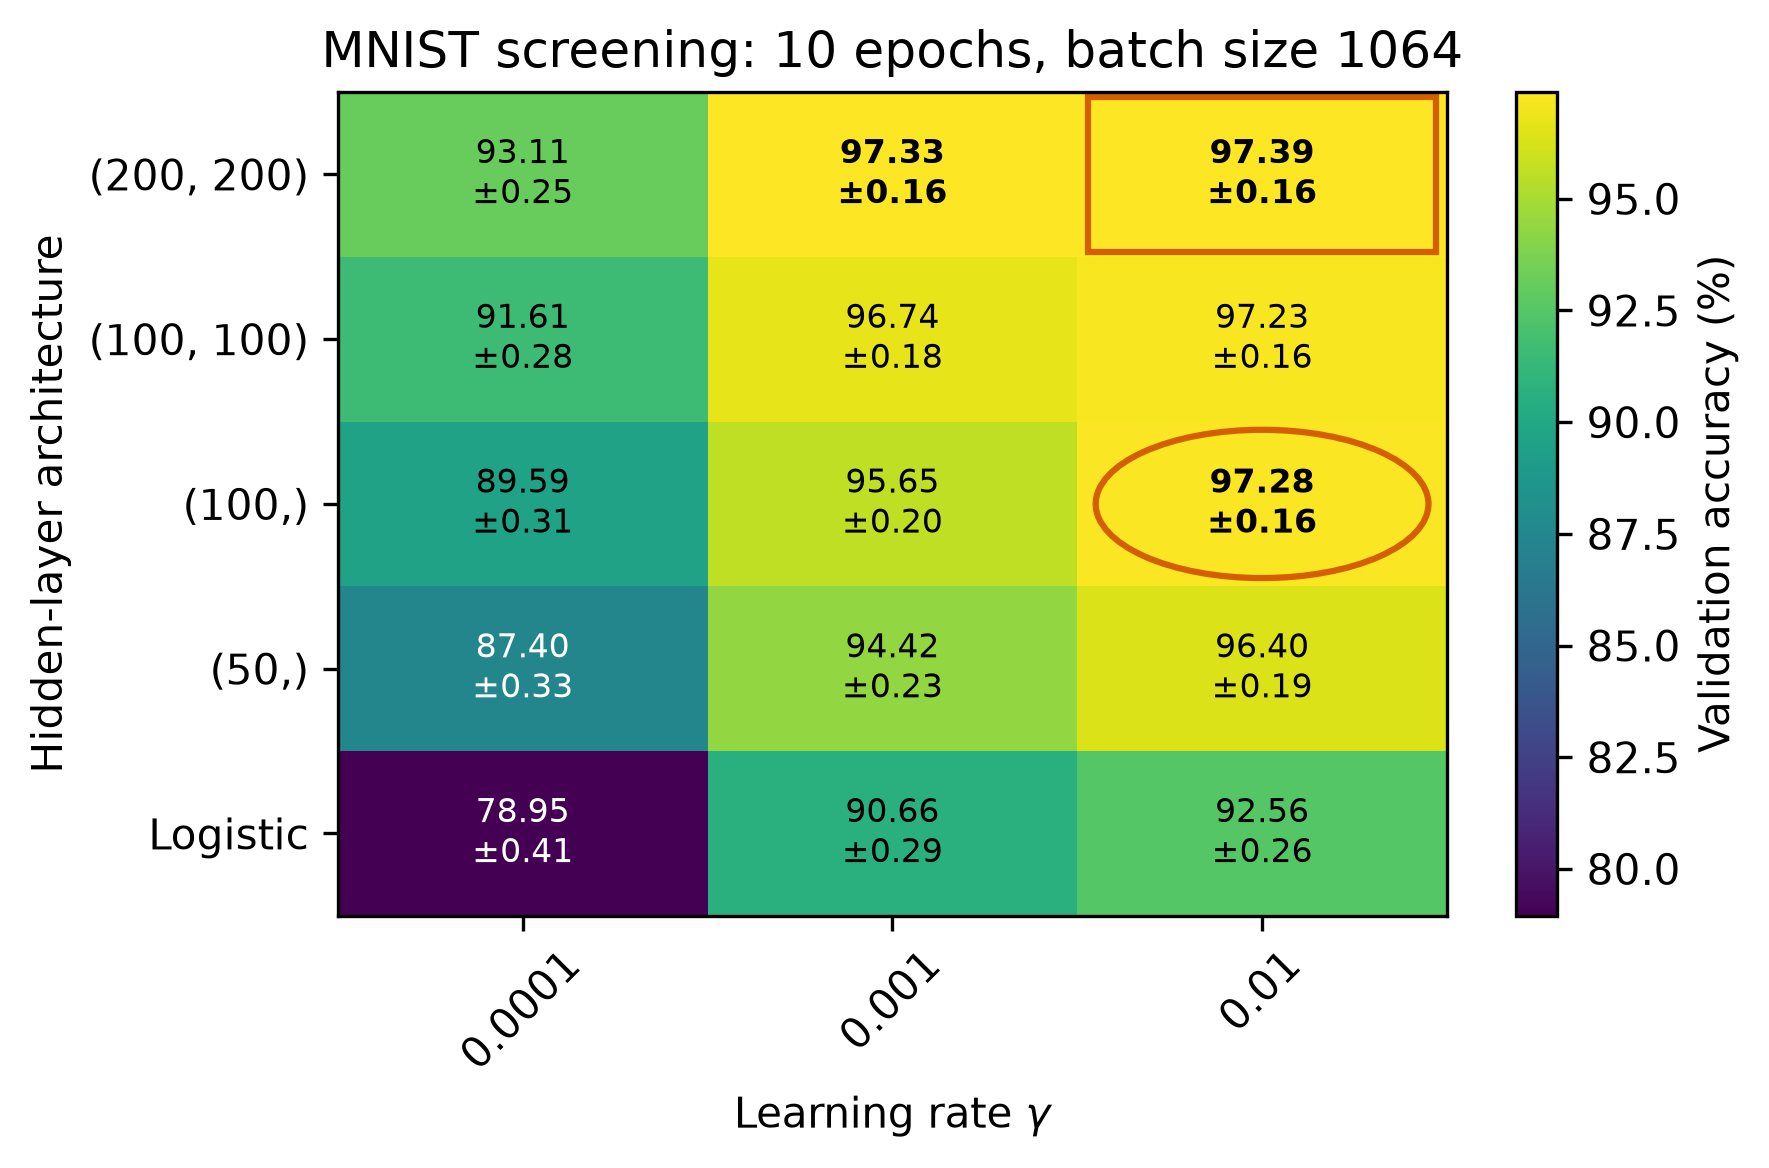

In [10]:
accuracy_e = np.full((len(ARCHITECTURES_E), len(GAMMAS_E)), np.nan)
se_e = np.full_like(accuracy_e, np.nan)

for row in screen_e:
    config = row["config"]
    a = ARCHITECTURES_E.index(config["hidden_sizes"])
    g = GAMMAS_E.index(config["gamma"])

    accuracy_e[a, g] = row["validation_accuracy"]
    se_e[a, g] = row["validation_se"]

maximum_e = max(
    screen_e,
    key=lambda row: row["validation_accuracy"],
)
threshold_e = maximum_e["validation_accuracy"] - maximum_e["validation_se"]

pilot_choice_e = min(
    [row for row in screen_e if row["validation_accuracy"] >= threshold_e],
    key=lambda row: (
        row["parameters"],
        len(row["config"]["hidden_sizes"]),
        -row["validation_accuracy"],
    ),
)

fig, ax = plt.subplots(figsize=(6, 4))

im = ax.imshow(100 * accuracy_e, origin="lower", cmap="viridis", aspect="auto")

ax.set_xticks(
    range(len(GAMMAS_E)),
    labels=[f"{gamma:g}" for gamma in GAMMAS_E],
    rotation=45,
)
ax.set_yticks(
    range(len(ARCHITECTURES_E)),
    labels=[str(hidden) if hidden else "Logistic" for hidden in ARCHITECTURES_E],
)

ax.set(
    xlabel=r"Learning rate $\gamma$",
    ylabel="Hidden-layer architecture",
    title=f"MNIST screening: {SCREEN_EPOCHS_E} epochs, batch size {BATCH_SIZE_E}",
)

for a, g in np.ndindex(accuracy_e.shape):
    value = accuracy_e[a, g]

    ax.text(
        g,
        a,
        f"{100 * value:.2f}\n±{100 * se_e[a, g]:.2f}",
        ha="center",
        va="center",
        fontsize=8,
        color="black" if im.norm(100 * value) > 0.5 else "white",
        fontweight="bold" if value >= threshold_e else "normal",
    )

for row, shape in [
    (maximum_e, "square"),
    (pilot_choice_e, "circle"),
]:
    config = row["config"]
    a = ARCHITECTURES_E.index(config["hidden_sizes"])
    g = GAMMAS_E.index(config["gamma"])

    if shape == "square":
        patch = Rectangle(
            (g - 0.47, a - 0.47), 0.94, 0.94, fill=False, edgecolor=RED, linewidth=1.5
        )
    else:
        patch = Ellipse((g, a), 0.9, 0.9, fill=False, edgecolor=RED, linewidth=1.5)

    ax.add_patch(patch)

fig.colorbar(im, ax=ax, label="Validation accuracy (%)")

fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_e_screening.pdf")
plt.show()

In [11]:
PROMISING_E = [(100,), (200, 200)]
GAMMA_FOLLOWUP_E = 0.01

base_rows_e = [
    next(
        row
        for row in screen_e
        if row["config"]["hidden_sizes"] == hidden
        and np.isclose(row["config"]["gamma"], GAMMA_FOLLOWUP_E)
        and row["config"]["activation"] == "ReLU"
    )
    for hidden in PROMISING_E
]

activation_configs_e = [
    {**row["config"], "activation": activation, "lmbd1": 0.0, "lmbd2": 0.0}
    for row in base_rows_e
    for activation in ("Sigmoid", "Leaky ReLU")
]

activation_e = part_e.run_search(
    X_train_e,
    Y_train_e,
    X_val_e,
    Y_val_e,
    activation_configs_e,
    epochs=SCREEN_EPOCHS_E,
    batch_size=BATCH_SIZE_E,
    seed=SEED,
)

activation_rows_e = base_rows_e + activation_e

In [28]:
from matplotlib.patches import Rectangle


def plot_validation_heatmap(
    values,
    errors,
    row_labels,
    column_labels,
    title,
    filename,
):
    fig, ax = plt.subplots(figsize=(7, 3))

    im = ax.imshow(
        100 * values,
        cmap="viridis",
        aspect="auto",
    )

    ax.set_xticks(
        range(len(column_labels)),
        labels=column_labels,
    )
    ax.set_yticks(
        range(len(row_labels)),
        labels=row_labels,
    )
    ax.set_title(title)

    for row in range(values.shape[0]):
        best = int(np.nanargmax(values[row]))
        threshold = values[row, best] - errors[row, best]

        for col in range(values.shape[1]):
            value = values[row, col]

            ax.text(
                col,
                row,
                f"{100 * value:.2f}\n±{100 * errors[row, col]:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color=("black" if im.norm(100 * value) > 0.5 else "white"),
                fontweight=("bold" if value >= threshold else "normal"),
            )

        ax.add_patch(
            Rectangle(
                (best - 0.47, row - 0.47),
                0.94,
                0.94,
                fill=False,
                edgecolor=RED,
                linewidth=1.5,
            )
        )

    fig.colorbar(im, ax=ax, label="Validation accuracy (%)")

    fig.text(
        0.5,
        0.01,
        "Cells: accuracy ± SE (%). Bold: within one SE of row maximum. Square: maximum.",
        ha="center",
        fontsize=7,
    )

    fig.tight_layout(rect=(0, 0.07, 1, 1))
    save_figure(fig, FIGURES_DIR, filename)
    plt.show()

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_e_activation_followup.pdf


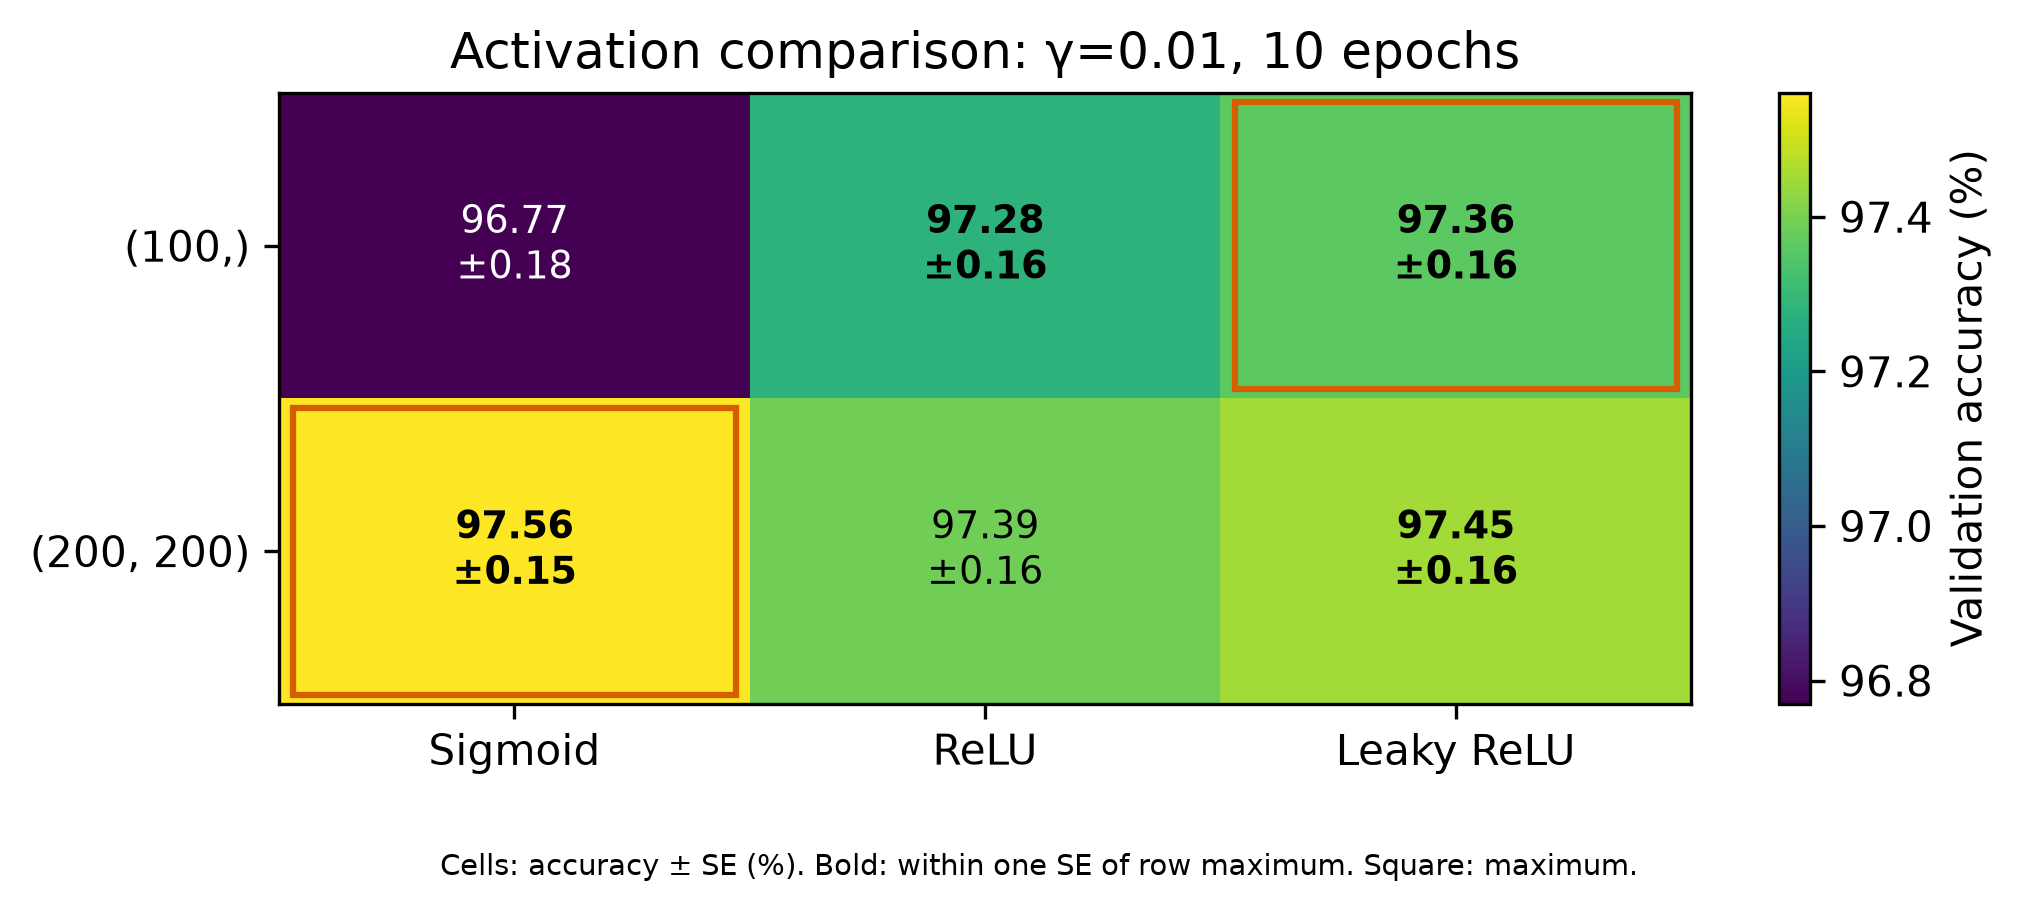

In [29]:
activation_names_e = list(part_e.ACTIVATIONS)

activation_accuracy_e = np.empty((len(PROMISING_E), len(activation_names_e)))
activation_se_e = np.empty_like(activation_accuracy_e)

best_activation_e = []

for a, hidden in enumerate(PROMISING_E):
    rows = [row for row in activation_rows_e if row["config"]["hidden_sizes"] == hidden]

    best_activation_e.append(max(rows, key=lambda row: row["validation_accuracy"]))

    for col, name in enumerate(activation_names_e):
        row = next(row for row in rows if row["config"]["activation"] == name)
        activation_accuracy_e[a, col] = row["validation_accuracy"]
        activation_se_e[a, col] = row["validation_se"]

plot_validation_heatmap(
    activation_accuracy_e,
    activation_se_e,
    [str(hidden) for hidden in PROMISING_E],
    activation_names_e,
    f"Activation comparison: γ={GAMMA_FOLLOWUP_E:g}, {SCREEN_EPOCHS_E} epochs",
    filename="part_e_activation_followup.pdf",
)

In [14]:
penalty_configs_e = [
    {
        **row["config"],
        "lmbd1": lmbd if penalty == "L1" else 0.0,
        "lmbd2": lmbd if penalty == "L2" else 0.0,
    }
    for row in best_activation_e
    for penalty in ("L1", "L2")
    for lmbd in LAMBDAS_E
]

penalty_e = part_e.run_search(
    X_train_e,
    Y_train_e,
    X_val_e,
    Y_val_e,
    penalty_configs_e,
    epochs=SCREEN_EPOCHS_E,
    batch_size=BATCH_SIZE_E,
    seed=SEED,
)

penalty_rows_e = best_activation_e + penalty_e

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_e_regularization_followup.pdf


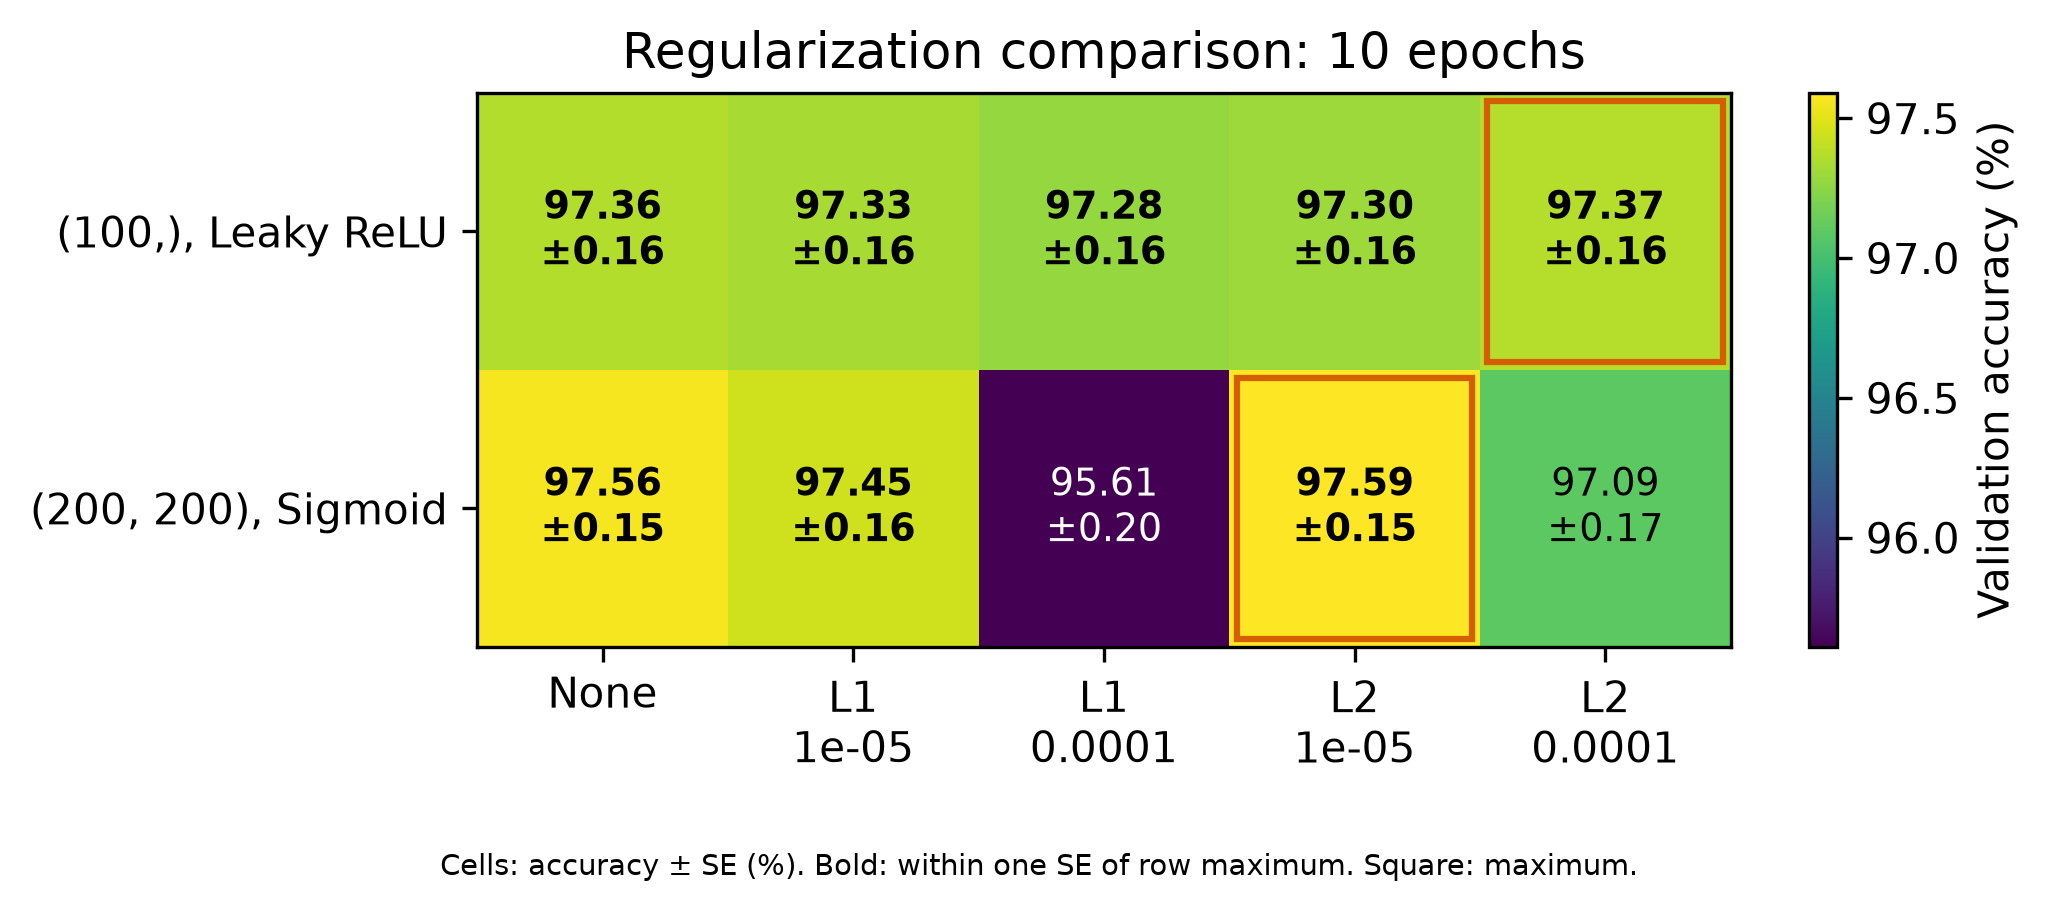

In [30]:
penalty_settings_e = (
    [(0.0, 0.0)] + [(lmbd, 0.0) for lmbd in LAMBDAS_E] + [(0.0, lmbd) for lmbd in LAMBDAS_E]
)

penalty_labels_e = (
    ["None"] + [f"L1\n{lmbd:g}" for lmbd in LAMBDAS_E] + [f"L2\n{lmbd:g}" for lmbd in LAMBDAS_E]
)

penalty_accuracy_e = np.empty(
    (
        len(PROMISING_E),
        len(penalty_settings_e),
    )
)
penalty_se_e = np.empty_like(penalty_accuracy_e)

finalist_configs_e = []

for a, hidden in enumerate(PROMISING_E):
    rows = [row for row in penalty_rows_e if row["config"]["hidden_sizes"] == hidden]

    finalist_configs_e.append(
        max(
            rows,
            key=lambda row: row["validation_accuracy"],
        )["config"]
    )

    for col, (l1, l2) in enumerate(penalty_settings_e):
        row = next(
            row
            for row in rows
            if np.isclose(row["config"].get("lmbd1", 0.0), l1)
            and np.isclose(row["config"].get("lmbd2", 0.0), l2)
        )

        penalty_accuracy_e[a, col] = row["validation_accuracy"]
        penalty_se_e[a, col] = row["validation_se"]

plot_validation_heatmap(
    penalty_accuracy_e,
    penalty_se_e,
    [
        f"{hidden}, {row['config']['activation']}"
        for hidden, row in zip(PROMISING_E, best_activation_e)
    ],
    penalty_labels_e,
    f"Regularization comparison: {SCREEN_EPOCHS_E} epochs",
    filename="part_e_regularization_followup.pdf",
)

In [16]:
logistic_config_e = max(
    [row for row in screen_e if not row["config"]["hidden_sizes"]],
    key=lambda row: row["validation_accuracy"],
)["config"]

long_e = part_e.run_search(
    X_train_e,
    Y_train_e,
    X_val_e,
    Y_val_e,
    [logistic_config_e] + finalist_configs_e,
    epochs=LONG_EPOCHS_E,
    batch_size=BATCH_SIZE_E,
    seed=SEED,
)

selected_e = {
    "Our logistic": part_e.select_model(
        [row for row in long_e if not row["config"]["hidden_sizes"]],
        len(Y_val_e),
    ),
    "Our FFNN": part_e.select_model(
        [row for row in long_e if row["config"]["hidden_sizes"]],
        len(Y_val_e),
    ),
}

for name, row in selected_e.items():
    print(
        name,
        row["config"],
        "epochs:",
        row["epochs"],
        "validation accuracy:",
        f"{row['validation_accuracy']:.4f}",
    )

Our logistic {'lmbd1': 0.0, 'lmbd2': 0.0, 'hidden_sizes': (), 'activation': 'ReLU', 'gamma': 0.01} epochs: 6 validation accuracy: 0.9259
Our FFNN {'lmbd1': 0.0, 'lmbd2': 1e-05, 'hidden_sizes': (200, 200), 'activation': 'Sigmoid', 'gamma': 0.01} epochs: 27 validation accuracy: 0.9818


In [17]:
references_e = part_e.fit_references(
    X_train_e,
    Y_train_e,
    X_val_e,
    Y_val_e,
    selected_e["Our FFNN"],
    epochs=LONG_EPOCHS_E,
    batch_size=BATCH_SIZE_E,
    seed=SEED,
)

mlp_label_e = "Scikit-Learn MLP" if references_e["mlp_matched"] else "Scikit-Learn MLP reference"

print(mlp_label_e, references_e["mlp_config"], "epochs:", references_e["mlp_epochs"])

Scikit-Learn MLP {'lmbd1': 0.0, 'lmbd2': 1e-05, 'hidden_sizes': (200, 200), 'activation': 'Sigmoid', 'gamma': 0.01} epochs: 27


Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_e_learning_curves.pdf


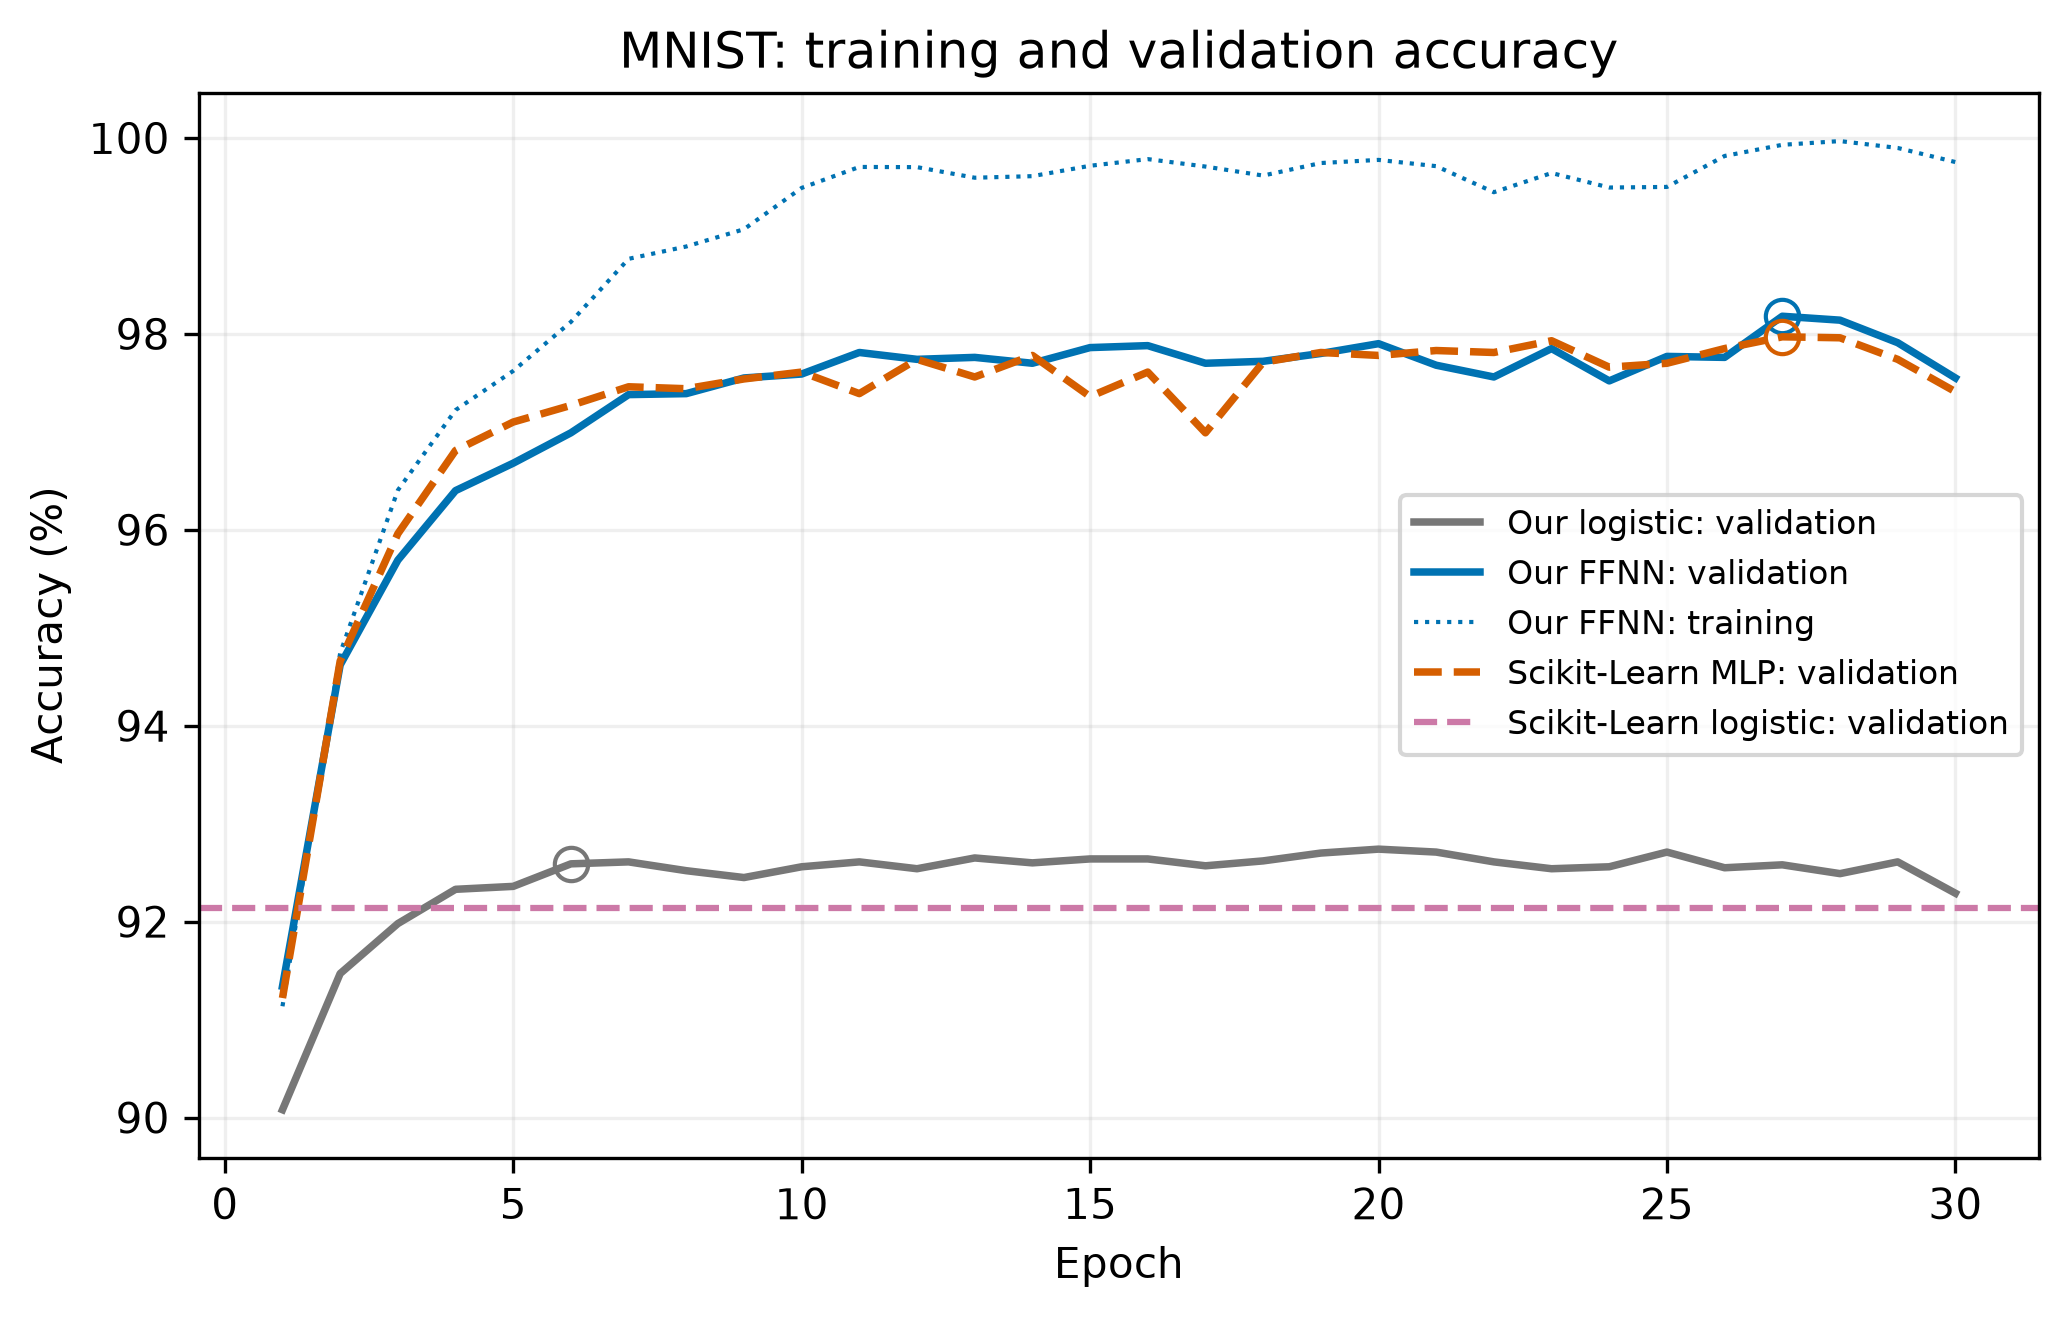

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for name, color in [
    ("Our logistic", GREY),
    ("Our FFNN", BLUE),
]:
    row = selected_e[name]
    history = row["history"]

    ax.plot(
        np.arange(1, len(history["val_accuracy"]) + 1),
        100 * np.asarray(history["val_accuracy"]),
        color=color,
        linewidth=1.8,
        label=f"{name}: validation",
    )

    ax.plot(
        row["epochs"],
        100 * row["validation_accuracy"],
        "o",
        markerfacecolor="none",
        markeredgecolor=color,
        markersize=8,
    )

ffnn_history_e = selected_e["Our FFNN"]["history"]

ax.plot(
    np.arange(1, len(ffnn_history_e["train_accuracy"]) + 1),
    100 * np.asarray(ffnn_history_e["train_accuracy"]),
    color=BLUE,
    linestyle=":",
    linewidth=1,
    label="Our FFNN: training",
)

ax.plot(
    np.arange(1, len(references_e["mlp_history"]) + 1),
    100 * np.asarray(references_e["mlp_history"]),
    color=RED,
    linestyle="--",
    linewidth=1.8,
    label=f"{mlp_label_e}: validation",
)

ax.plot(
    references_e["mlp_epochs"],
    100 * references_e["mlp_validation_accuracy"],
    "o",
    markerfacecolor="none",
    markeredgecolor=RED,
    markersize=8,
)

ax.axhline(
    100 * references_e["logistic_validation_accuracy"],
    color=PURPLE,
    linestyle="--",
    label="Scikit-Learn logistic: validation",
)

ax.set(
    xlabel="Epoch",
    ylabel="Accuracy (%)",
    title="MNIST: training and validation accuracy",
)
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_e_learning_curves.pdf")
plt.show()

In [20]:
from project2.utils import save_wide_table

final_e = part_e.final_comparison(
    X_all_e,
    Y_all_e,
    X_test_e,
    y_test_e,
    selected_e,
    references_e,
    batch_size=BATCH_SIZE_E,
    seed=SEED,
)

classification_table_e = pd.DataFrame(final_e["records"])

report_table_e = classification_table_e.rename(
    columns={
        "Parameters": "Params",
        "Fit time (s)": "Time (s)",
        "Test accuracy": "Test acc.",
    }
)

display(report_table_e)

config_e = selected_e["Our FFNN"]["config"]
config_mlp_e = references_e["mlp_config"]

caption_e = (
    "MNIST test results after refitting fixed models on all "
    "60,000 training images. Accuracy and macro-F1 are fractions. "
    "Times are refit wall times. "
    f"Selected FFNN: {config_e['activation']}, "
    f"gamma={config_e['gamma']:g}, "
    f"L1={config_e.get('lmbd1', 0):g}, "
    f"L2={config_e.get('lmbd2', 0):g}, "
    f"{selected_e['Our FFNN']['epochs']} epochs. "
    f"MLP: {config_mlp_e['activation']}, "
    f"gamma={config_mlp_e['gamma']:g}, "
    f"L2={config_mlp_e.get('lmbd2', 0):g}, "
    f"{references_e['mlp_epochs']} epochs."
)

save_wide_table(
    report_table_e,
    TABLES_DIR,
    "part_e_final_comparison.tex",
    caption=caption_e,
    label="part_e_final_comparison",
)

,Model,Architecture,Params,Time (s),Test acc.,Macro F1
0,Our logistic,(),7850,8.044988,0.9245,0.923462
1,Our FFNN,"(200, 200)",199210,89.701154,0.9788,0.978704
2,Scikit-Learn logistic,(),7850,540.038483,0.9252,0.924164
3,Scikit-Learn MLP,"(200, 200)",199210,43.865157,0.9766,0.976556


Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/report/tables/part_e_final_comparison.tex
Use in main.tex: \input{tables/part_e_final_comparison.tex}


PosixPath('/home/hmmorad/school/STK/fys-stk3155/projects/project2/report/tables/part_e_final_comparison.tex')

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_e_confusion_matrix.pdf


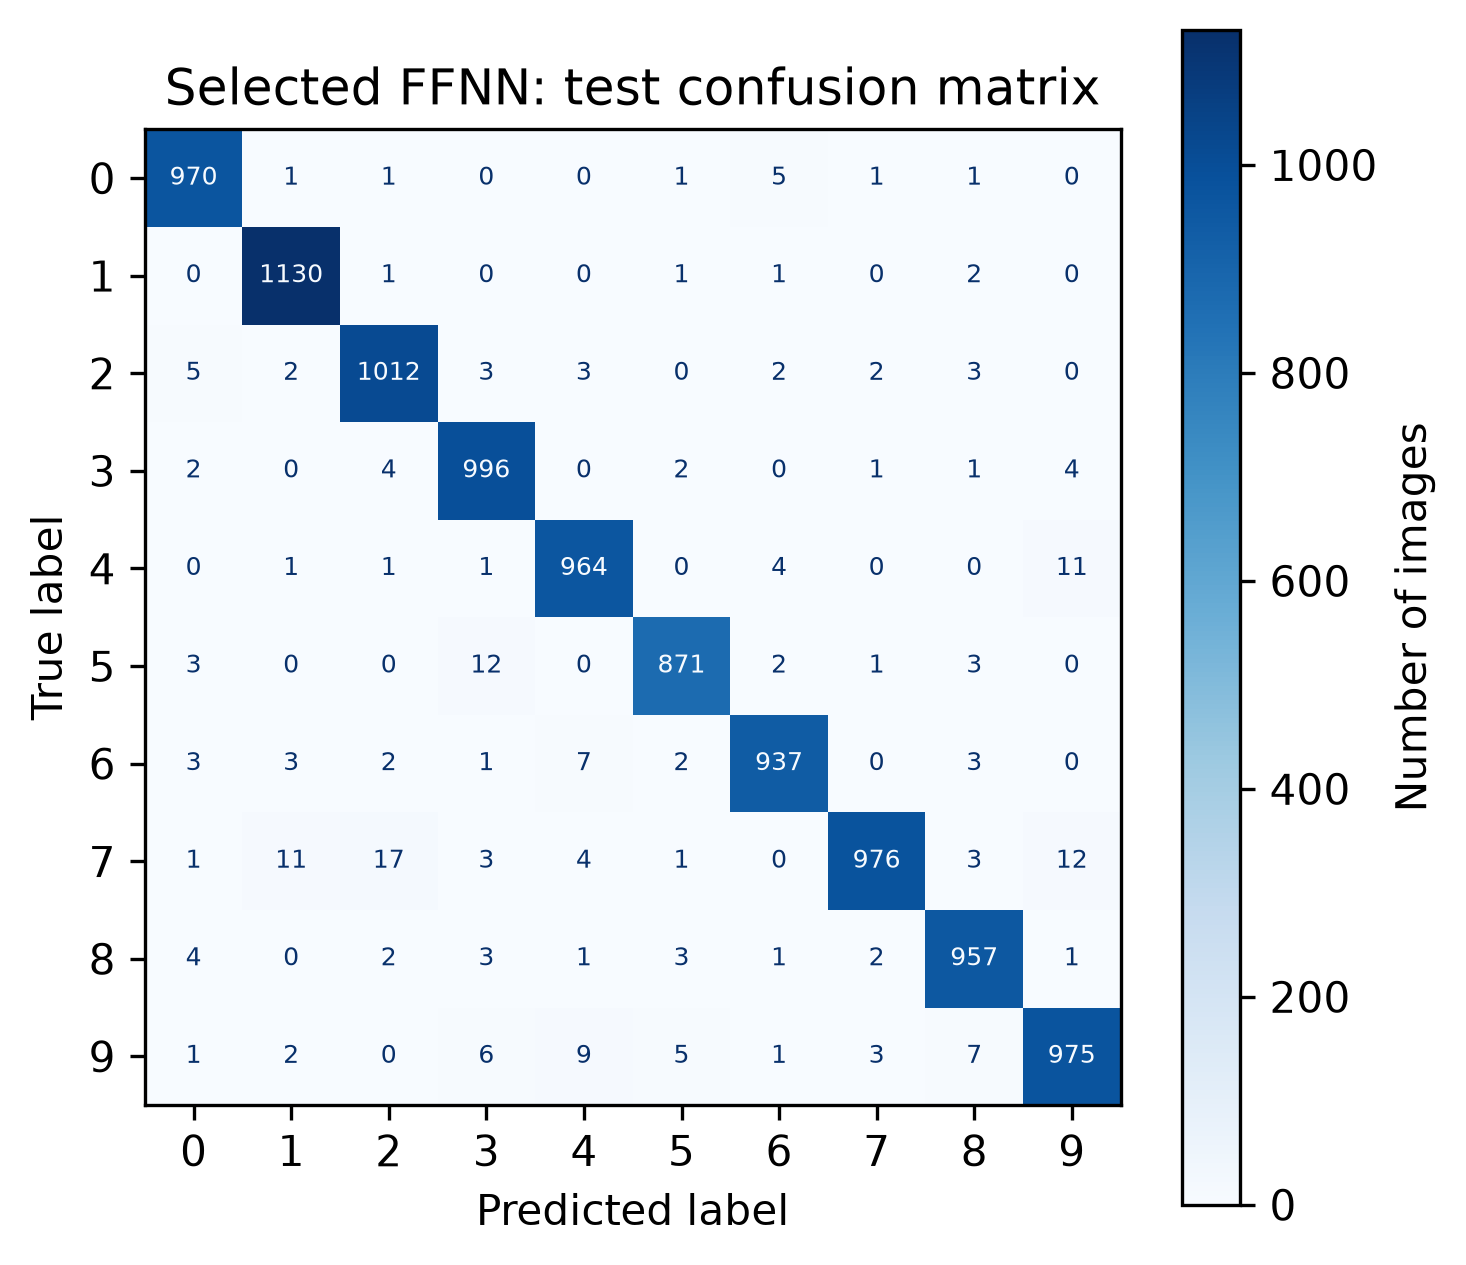

Correct predictions: 9788 / 10000
True 7 → predicted 2: 17 images
True 7 → predicted 9: 12 images
True 5 → predicted 3: 12 images


In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

prediction_e = final_e["predictions"]["Our FFNN"]

counts_e = confusion_matrix(
    y_test_e,
    prediction_e,
    labels=np.arange(10),
)

fig, ax = plt.subplots(figsize=(5, 4.5))

cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test_e,
    prediction_e,
    labels=np.arange(10),
    normalize=None,
    cmap="Blues",
    values_format="d",
    ax=ax,
)

for text in cm_display.text_.ravel():
    text.set_fontsize(6)

cm_display.im_.colorbar.set_label("Number of images")

ax.set_title("Selected FFNN: test confusion matrix")
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_e_confusion_matrix.pdf")
plt.show()

print(f"Correct predictions: {np.trace(counts_e)} / {counts_e.sum()}")

pairs_e = [(counts_e[i, j], i, j) for i in range(10) for j in range(10) if i != j]

for count, true_digit, predicted_digit in sorted(pairs_e, reverse=True)[:3]:
    if count:
        print(f"True {true_digit} → predicted {predicted_digit}: {count} images")

Saved: /home/hmmorad/school/STK/fys-stk3155/projects/project2/figures/part_e_confused_4_9.pdf


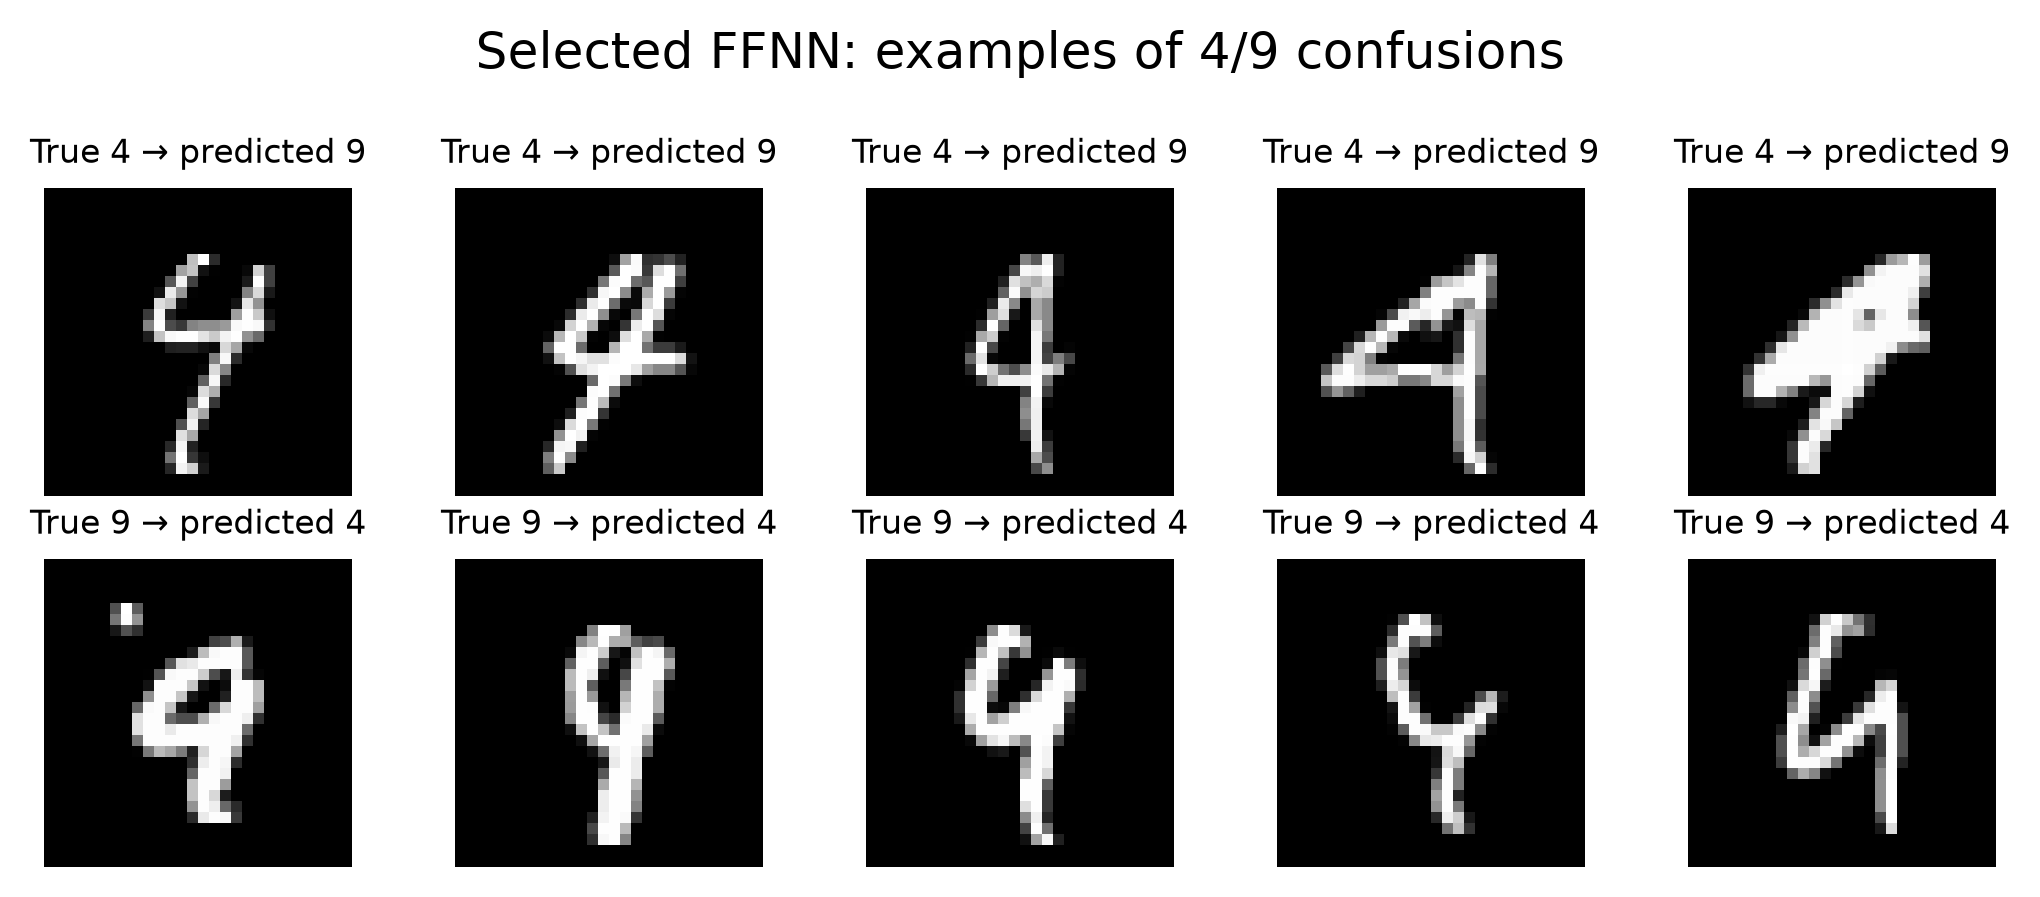

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(7, 3))
rng_errors = np.random.default_rng(SEED)

for row, (true_digit, predicted_digit) in enumerate(
    [
        (4, 9),
        (9, 4),
    ]
):
    errors = np.flatnonzero((y_test_e == true_digit) & (prediction_e == predicted_digit))

    examples = rng_errors.choice(
        errors,
        size=min(5, len(errors)),
        replace=False,
    )

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(examples):
            ax.imshow(
                images_test_e[examples[col]],
                cmap="gray",
            )
            ax.set_title(
                f"True {true_digit} → predicted {predicted_digit}",
                fontsize=8,
            )
        elif col == 0:
            ax.text(
                0.5,
                0.5,
                f"No {true_digit} → {predicted_digit} errors",
                ha="center",
                va="center",
                fontsize=9,
            )

fig.suptitle("Selected FFNN: examples of 4/9 confusions")
fig.tight_layout()

save_figure(fig, FIGURES_DIR, "part_e_confused_4_9.pdf")
plt.show()